# Sephora Recommender System
**Item ranking and rating predictions**

<b>Analysis Context:</b>

The global beauty market is growing steadily and rapidly undergoing digital transformation. As beauty product consumption rises, brands must adapt strategically as traditional, often region-based consumer profiles give way to more diverse, heterogeneous preferences. This shift demands deeper personalisation and a more differentiated, compelling shopping experience tailored to individual relevance.
Personalisation is especially relevant in beauty e-commerce, where online purchases make product discovery even more essential. Sephora, a leading platform for premium beauty and skincare products, leverages customer profiles, virtual product trials, and personalised recommendations based on individual beauty traits. These strategies create an experiential, hyperpersonalised user experience that enhances performance, customer satisfaction, and fosters long-term customer relationships.

<b>Customer Challenge:</b>

Even on a digitally sophisticated beauty platform like Sephora, offering a broad skincare product catalogue, customers with diverse preferences may still struggle with product discovery and choice. Leveraging customer rating behaviour—and testing whether enriching it with customer and product context improves it further—can help rank products an individual is likely to value based on observed preferences, supporting more personalised purchases and potentially driving conversion.

<b>Analysis Objective:</b>

This analysis aims to determine how effectively classical machine learning and deep learning approaches can generate personalised Sephora skincare recommendations. The task is evaluated on two aspects: 

* **Rating prediction:** *How accurately a model estimates a customer's preference strength*
* **Item ranking:** *How useful the recommended order is to the customer*

<b>Business Analytical Question:</b>

How can customer explicit rating behaviour be leveraged to support personalised product discovery across Sephora's product catalogue?


<b>Dataset used:</b>

Kaggle’s Sephora Products and Skincare Reviews (Inky, 2023) contains one product-specific dataset and five customer review files with customer ratings and review-specific information. This analysis uses only the review files as these provide the key user-product interactions supporting a collaborative recommendation approach, along with product contextual information such as price and brand. The separate product file was not considered during this analysis.

## 1. Installing Packages

In [ ]:
# Install packages
%pip install -q kagglehub shap

# Core libraries
import os
import copy
import math
import random

# Data handling and visualisation
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
from sklearn.metrics import root_mean_squared_error

# PyTorch
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Explainability
import shap

# File download
import kagglehub

## 2. Data Loading
Dataset contains 5 review files split by volumes. Specifying data type for author_id which has a mixed dtype.

In [2]:
# Download dataset
path = kagglehub.dataset_download(
    'nadyinky/sephora-products-and-skincare-reviews'
)

# Load only the five review files needed
reviews_1 = pd.read_csv(
    os.path.join(path, 'reviews_0-250.csv'),
    dtype={'author_id': 'str'}
)

reviews_2 = pd.read_csv(
    os.path.join(path, 'reviews_250-500.csv'),
    dtype={'author_id': 'str'}
)

reviews_3 = pd.read_csv(
    os.path.join(path, 'reviews_500-750.csv'),
    dtype={'author_id': 'str'}
)

reviews_4 = pd.read_csv(
    os.path.join(path, 'reviews_750-1250.csv'),
    dtype={'author_id': 'str'}
)

reviews_5 = pd.read_csv(
    os.path.join(path, 'reviews_1250-end.csv'),
    dtype={'author_id': 'str'}
)

## 3. Data Understanding

In [3]:
# Inspect the first batch
reviews_1.head()

,Unnamed: 0,author_id,rating,is_recommended,helpfulness,total_feedback_count,total_neg_feedback_count,total_pos_feedback_count,submission_time,review_text,review_title,skin_tone,eye_color,skin_type,hair_color,product_id,product_name,brand_name,price_usd
0,0,1741593524,5,1.0,1.0,2,0,2,2023-02-01,I use this with the Nudestix “Citrus Clean Bal...,Taught me how to double cleanse!,NaN,brown,dry,black,P504322,Gentle Hydra-Gel Face Cleanser,NUDESTIX,19.0
1,1,31423088263,1,0.0,NaN,0,0,0,2023-03-21,I bought this lip mask after reading the revie...,Disappointed,NaN,NaN,NaN,NaN,P420652,Lip Sleeping Mask Intense Hydration with Vitam...,LANEIGE,24.0
2,2,5061282401,5,1.0,NaN,0,0,0,2023-03-21,My review title says it all! I get so excited ...,New Favorite Routine,light,brown,dry,blonde,P420652,Lip Sleeping Mask Intense Hydration with Vitam...,LANEIGE,24.0
3,3,6083038851,5,1.0,NaN,0,0,0,2023-03-20,I’ve always loved this formula for a long time...,Can't go wrong with any of them,NaN,brown,combination,black,P420652,Lip Sleeping Mask Intense Hydration with Vitam...,LANEIGE,24.0
4,4,47056667835,5,1.0,NaN,0,0,0,2023-03-20,"If you have dry cracked lips, this is a must h...",A must have !!!,light,hazel,combination,NaN,P420652,Lip Sleeping Mask Intense Hydration with Vitam...,LANEIGE,24.0


In [4]:
# Inspect reviews dimension 
reviews_1.shape


(602130, 19)

In [5]:
# Inspect reviews variable types 
reviews_1.info()

<class 'pandas.DataFrame'>
RangeIndex: 602130 entries, 0 to 602129
Data columns (total 19 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   Unnamed: 0                602130 non-null  int64  
 1   author_id                 602130 non-null  str    
 2   rating                    602130 non-null  int64  
 3   is_recommended            484644 non-null  float64
 4   helpfulness               270298 non-null  float64
 5   total_feedback_count      602130 non-null  int64  
 6   total_neg_feedback_count  602130 non-null  int64  
 7   total_pos_feedback_count  602130 non-null  int64  
 8   submission_time           602130 non-null  str    
 9   review_text               601131 non-null  str    
 10  review_title              435119 non-null  str    
 11  skin_tone                 496074 non-null  str    
 12  eye_color                 463642 non-null  str    
 13  skin_type                 527447 non-null  str    
 14 

In [6]:
# Inspect data types count per type category
reviews_1.dtypes.value_counts()

str        11
int64       5
float64     3
Name: count, dtype: int64

In [7]:
# Inspect summary statistics across all variables
reviews_1.describe(include='all')

,Unnamed: 0,author_id,rating,is_recommended,helpfulness,total_feedback_count,total_neg_feedback_count,total_pos_feedback_count,submission_time,review_text,review_title,skin_tone,eye_color,skin_type,hair_color,product_id,product_name,brand_name,price_usd
count,602130.000000,602130,602130.000000,484644.000000,270298.000000,602130.000000,602130.000000,602130.000000,602130,601131,435119,496074,463642,527447,461049,602130,602130,602130,602130.000000
unique,NaN,339017,NaN,NaN,NaN,NaN,NaN,NaN,5317,508467,202373,14,6,4,7,250,249,60,NaN
top,NaN,1696370280,NaN,NaN,NaN,NaN,NaN,NaN,2020-10-21,review message autotest,Love it!,light,brown,combination,brown,P420652,Lip Sleeping Mask Intense Hydration with Vitam...,Tatcha,NaN
freq,NaN,113,NaN,NaN,NaN,NaN,NaN,NaN,1451,13,3421,141402,243751,292308,218139,16138,16138,40681,NaN
mean,301064.500000,NaN,4.311838,0.837922,0.769722,3.660661,0.765473,2.895189,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,45.723937
std,173820.103131,NaN,1.143692,0.368522,0.319103,25.848330,4.968115,22.628880,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.743990
min,0.000000,NaN,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.000000
25%,150532.250000,NaN,4.000000,1.000000,0.666667,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.500000
50%,301064.500000,NaN,5.000000,1.000000,0.944444,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,38.000000
75%,451596.750000,NaN,5.000000,1.000000,1.000000,3.000000,0.000000,2.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,60.000000


In [8]:
# Validate and confirm if the data schema is the same across all reviews files 
for name, df in [
    ('0-250', reviews_1),
    ('250-500',reviews_2),
    ('500-750', reviews_3),
    ('750-1250', reviews_4),
    ('1250-end', reviews_5),

]:
    print(name)
    print('Shape:', df.shape)
    print('Columns:', list(df.columns))
    print()

0-250
Shape: (602130, 19)
Columns: ['Unnamed: 0', 'author_id', 'rating', 'is_recommended', 'helpfulness', 'total_feedback_count', 'total_neg_feedback_count', 'total_pos_feedback_count', 'submission_time', 'review_text', 'review_title', 'skin_tone', 'eye_color', 'skin_type', 'hair_color', 'product_id', 'product_name', 'brand_name', 'price_usd']

250-500
Shape: (206725, 19)
Columns: ['Unnamed: 0', 'author_id', 'rating', 'is_recommended', 'helpfulness', 'total_feedback_count', 'total_neg_feedback_count', 'total_pos_feedback_count', 'submission_time', 'review_text', 'review_title', 'skin_tone', 'eye_color', 'skin_type', 'hair_color', 'product_id', 'product_name', 'brand_name', 'price_usd']

500-750
Shape: (116262, 19)
Columns: ['Unnamed: 0', 'author_id', 'rating', 'is_recommended', 'helpfulness', 'total_feedback_count', 'total_neg_feedback_count', 'total_pos_feedback_count', 'submission_time', 'review_text', 'review_title', 'skin_tone', 'eye_color', 'skin_type', 'hair_color', 'product_id',

All files contain different numbers of reviews, but they share the same 19 variables and column structure, hence merging them into a single reviews dataset.

In [9]:
# Group all review files

reviews = pd.concat([reviews_1, reviews_2, reviews_3, reviews_4, reviews_5], ignore_index=True)

# Validate dimension
reviews.shape

(1094411, 19)

In [10]:
# Remove index column 
reviews = reviews.drop(columns='Unnamed: 0')

In [11]:
# Inspect reviews variable types 
reviews.info()

<class 'pandas.DataFrame'>
RangeIndex: 1094411 entries, 0 to 1094410
Data columns (total 18 columns):
 #   Column                    Non-Null Count    Dtype  
---  ------                    --------------    -----  
 0   author_id                 1094411 non-null  str    
 1   rating                    1094411 non-null  int64  
 2   is_recommended            926423 non-null   float64
 3   helpfulness               532819 non-null   float64
 4   total_feedback_count      1094411 non-null  int64  
 5   total_neg_feedback_count  1094411 non-null  int64  
 6   total_pos_feedback_count  1094411 non-null  int64  
 7   submission_time           1094411 non-null  str    
 8   review_text               1092967 non-null  str    
 9   review_title              783757 non-null   str    
 10  skin_tone                 923872 non-null   str    
 11  eye_color                 884783 non-null   str    
 12  skin_type                 982854 non-null   str    
 13  hair_color                867643 non-n

In [12]:
# Convert submission time to datetime
reviews['submission_time'] = pd.to_datetime(
    reviews['submission_time']
)

In [13]:
# Check data types count per type category
reviews.dtypes.value_counts()

str               10
int64              4
float64            3
datetime64[us]     1
Name: count, dtype: int64

In [14]:
#Validate combined reviews dimension
reviews.shape

(1094411, 18)

In [15]:
#Checking columns names
reviews.columns

Index(['author_id', 'rating', 'is_recommended', 'helpfulness',
       'total_feedback_count', 'total_neg_feedback_count',
       'total_pos_feedback_count', 'submission_time', 'review_text',
       'review_title', 'skin_tone', 'eye_color', 'skin_type', 'hair_color',
       'product_id', 'product_name', 'brand_name', 'price_usd'],
      dtype='str')

The merged review dataset contains ~1.1M observations with 18 attributes such as reviewer id, product id, explicit preference expressed via rating required for the recommender system models. The dataset also contains basic product metadata such as price, brand and name and review engagement information that is outside of the modelling scope.

## 4. Data Quality Assessment

### 4.1. Data type, Missingness and Unique Values

In [16]:
# Reviews Overview: Data type, Missingness and Unique Values

reviews_overview = pd.DataFrame({
    'Data Type': reviews.dtypes,
    'Missing Count': reviews.isna().sum(),
    'Missing %': (reviews.isna().mean() * 100).round(2),
    'Unique Values': reviews.nunique()}
) 

reviews_overview

,Data Type,Missing Count,Missing %,Unique Values
author_id,str,0,0.00,503216
rating,int64,0,0.00,5
is_recommended,float64,167988,15.35,2
helpfulness,float64,561592,51.31,3767
total_feedback_count,int64,0,0.00,676
total_neg_feedback_count,int64,0,0.00,259
total_pos_feedback_count,int64,0,0.00,590
submission_time,datetime64[us],0,0.00,5317
review_text,str,1444,0.13,969419
review_title,str,310654,28.39,364105


### 4.2. Duplications

In [17]:
# Inspect duplicates
reviews.duplicated().sum()

np.int64(224)

#### 4.2.1. Duplictaed User-Product Interactions
Inspecting whether a user has left multiple reviews for the same product. 
*Note: I treat author_id as 'user' in this notebook.*

In [18]:
# Inspect potential duplicated reviews from the same user for the same product
duplicated_pairs = reviews.duplicated(subset=['author_id', 'product_id'], keep = False)

print('Duplicated pairs:', duplicated_pairs.sum())

Duplicated pairs: 10478


In [19]:
# Inspect how many unique user-product pairs are affected

unique_duplicated_pairs = (
    reviews.loc[duplicated_pairs, ['author_id', 'product_id']]
    .drop_duplicates()
    .shape[0]
)
print('Unique duplicated pairs:', unique_duplicated_pairs)


Unique duplicated pairs: 4953


In [20]:
# Calculate total number of unique user-product pairs
total_unique_pairs = (reviews[['author_id', 'product_id']].drop_duplicates().shape[0])
print('Total unique pairs:', total_unique_pairs)

Total unique pairs: 1088886


In [21]:
# Calculate percentage of unique user-product pairs across all review records
total_unique_pairs_pct = (total_unique_pairs / len(reviews) *100)

# Calculate Percentage of all reviews involved in repaeated user-product pairs
duplicated_pairs_pct = duplicated_pairs.mean()*100 

# Calculate Percentage of unique user-product pairs that are repeated
unique_duplicated_pairs_pct = (unique_duplicated_pairs / total_unique_pairs *100)

print(f'Unique user-product pairs: {total_unique_pairs:,} ({total_unique_pairs_pct:.2f}%)')
print(f'Duplicated pairs: {duplicated_pairs.sum():,} ({duplicated_pairs_pct:.2f}%)')
print(f'Unique duplicated pairs: {unique_duplicated_pairs:,} ({unique_duplicated_pairs_pct:.2f}%)')

Unique user-product pairs: 1,088,886 (99.50%)
Duplicated pairs: 10,478 (0.96%)
Unique duplicated pairs: 4,953 (0.45%)


#### 4.2.2. Rating Investigation across Duplicated User-Product Pairs

In [22]:
#Assessing whether rating changes within the duplicated pairs. 

repeated_pairs = reviews.loc[duplicated_pairs]

changed_rating = (
    repeated_pairs.groupby(['author_id', 'product_id'])['rating']
    .nunique()
)

changed_rating.value_counts().sort_index()

rating
1    3789
2    1154
3       9
4       1
Name: count, dtype: int64

In [23]:
# Calulate percentage of rating changes across duplicated pairs
different_rating_pct = changed_rating.value_counts(normalize=True).sort_index() * 100
different_rating_pct

rating
1    76.499091
2    23.299011
3     0.181708
4     0.020190
Name: proportion, dtype: float64

In [24]:
# Calulate percentage of same vs different rating across duplicated pairs
same_rating = (changed_rating == 1).sum()
different_rating = (changed_rating > 1).sum ()

print(f'Same rating: {same_rating:,} ({same_rating / len(changed_rating) *100:.2f}%)')
print(f'Different rating: {different_rating:,} ({different_rating / len(changed_rating) *100:.2f}%)')


Same rating: 3,789 (76.50%)
Different rating: 1,164 (23.50%)


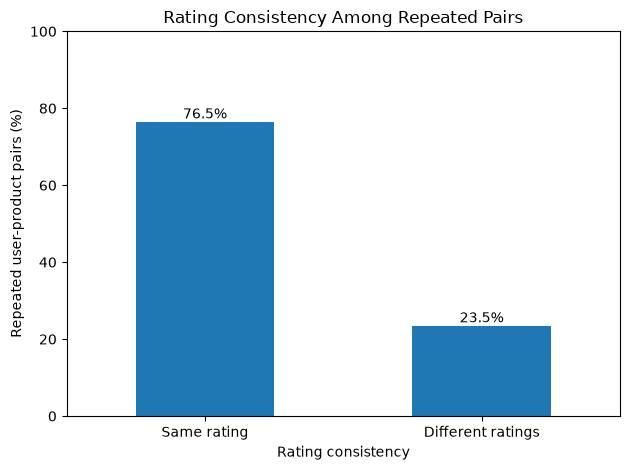

In [25]:
# Visulise duplicated pairs
same_rating = (changed_rating == 1).sum()
different_rating = (changed_rating > 1).sum()

percentages = pd.Series({
    'Same rating': same_rating / len(changed_rating) * 100,
    'Different ratings': different_rating / len(changed_rating) * 100
})

percentages.plot(kind='bar')

plt.xlabel('Rating consistency')
plt.ylabel('Repeated user-product pairs (%)')
plt.title('Rating Consistency Among Repeated Pairs')
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.gca().set_axisbelow(True)

for i, value in enumerate(percentages):
    plt.text(i, value, f'{value:.1f}%', ha='center', va='bottom')

plt.tight_layout()
plt.show()

**Reviews Quality Assessment - Summary:**

The dataset contains 503K unique users and 2.3K unique products, no missingness is established in the key modelling attributes. Missingness is detected in additional contextual information such as reviewer profile traits like skin tone (16%), skin type (10%), hair colour (21%), eye colour (19%) information affecting audit coverage. Higher missingness is established in review engagement attributes such as helpfulness (50%), as well as review title and text, but these attributes are not critical to this analysis.

Most interactions (99.5%) occur only once per user-product pair and duplicated interactions affect only a small proportion of review records (0.96%). Most duplicated pairs retain the same preference signal (76%), while one quarter (24%) of the repeated pairs have changed ratings, hence these are treated as repeated user–product pairs, rather than duplicate review records.

**Initial attributes role:**
* Core interactions:*author_id, product_id, rating*
* Product context: *product_name, braiduct_brand, product_price*
* Potential preference signal: *is_recommended* (recommendation flag)
* Temporal evaluation: *submission_time* (review date)
* Subgroup attributes: *skin_tone, (potentially skin_type, hair_color, eye_color)*
* Outside of scope: *helpfulness, total_feedback_count, total_neg_feedback_count, total_pos_feedback_count, review_text, review_title*

In [26]:
#Droping Variables out of modelling scope
columns_to_drop = [
    'helpfulness', 'total_feedback_count', 'total_neg_feedback_count', 'total_pos_feedback_count', 'review_text', 'review_title' 
]

reviews = reviews.drop(columns=columns_to_drop)

In [27]:
reviews.shape

(1094411, 12)

## 5. Exploratory Data Analysis (EDA)

### 5.1. Rating Distribution - Target 

In [28]:
# Evaluate Rating distribution
reviews['rating'].describe().round(2)

count    1094411.00
mean           4.30
std            1.15
min            1.00
25%            4.00
50%            5.00
75%            5.00
max            5.00
Name: rating, dtype: float64

In [29]:
# Calculate rating counts and percentage
rating_distribution = (
    reviews['rating']
    .value_counts()
    .sort_index()
    .to_frame('count')
)

rating_distribution['percentage'] = (
    rating_distribution['count'] / len(reviews) * 100
    ).round(2)

rating_distribution

,count,percentage
rating,,
1,61223,5.59
2,53032,4.85
3,81816,7.48
4,199389,18.22
5,698951,63.87


In [30]:
high_rating_pct = (reviews['rating'].isin([4, 5]).mean() *100)

print(f'Ratings 4-5: {high_rating_pct:.2f}%')

Ratings 4-5: 82.08%


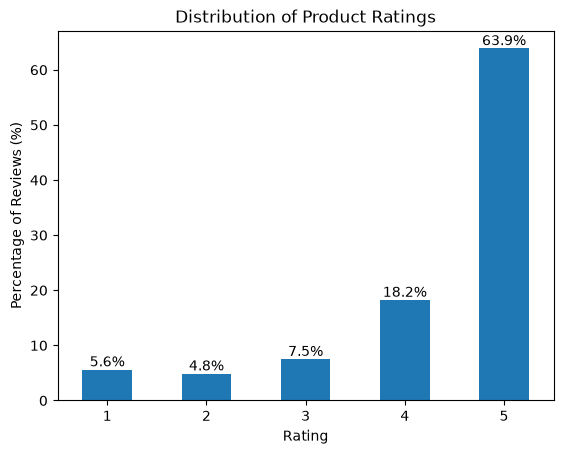

In [31]:
# Visualise Rating distribution

rating_distribution['percentage'].plot(kind = 'bar')

plt.xlabel('Rating')
plt.ylabel('Percentage of Reviews (%)')
plt.title('Distribution of Product Ratings')
plt.xticks(rotation=0)

for i, value in enumerate(rating_distribution['percentage']):
    plt.text(i, value, f'{value:.1f}%', ha ='center', va='bottom')

plt.show()

The rating distribution is strongly left-skewed (negatively skewed), with most ratings (82%) concentrated at the higher end of the 1-5 scale, particularly at 5 (64%). This indicates an imbalanced explicit rating signal.

### 5.2. Temporal Pattern
Assessing reviews distributed and coverage over time.

In [32]:
# Check Temporal distribution
reviews['submission_time'].describe()


count                       1094411
mean     2019-10-22 12:07:39.508538
min             2008-08-28 00:00:00
25%             2018-10-14 00:00:00
50%             2020-06-11 00:00:00
75%             2021-10-13 00:00:00
max             2023-03-21 00:00:00
Name: submission_time, dtype: object

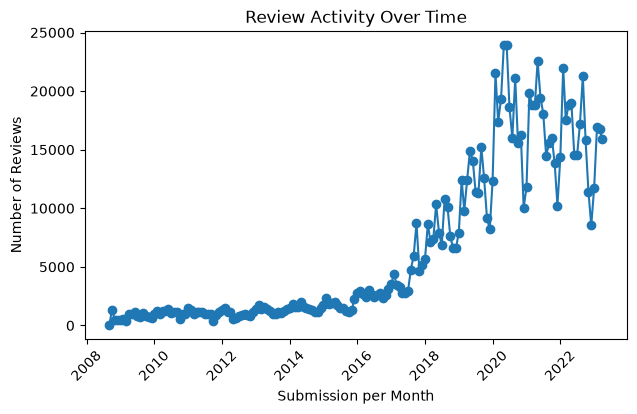

In [33]:
# Aggregate Reviews Activity per month
reviews_per_month =(
    reviews
    .set_index('submission_time')
    .resample('ME')
    .size()
)

# Visualise Reviews Activity Distribution
plt.figure(figsize=(7, 4))

plt.plot(reviews_per_month.index, reviews_per_month.values, marker="o")
plt.xlabel("Submission per Month")
plt.ylabel("Number of Reviews")
plt.title("Review Activity Over Time")
plt.xticks(rotation=45)
plt.show()

In [34]:
# Aggregate Reviews Activity per year
reviews_per_year =(
    reviews.groupby(reviews['submission_time'].dt.year)
    .size() 
)

reviews_per_year

submission_time
2008      2761
2009      9709
2010     13485
2011     12417
2012     11800
2013     15621
2014     18224
2015     21590
2016     33137
2017     54592
2018     97996
2019    143860
2020    215449
2021    202012
2022    192227
2023     49531
dtype: int64

In [35]:
# Calulate Percentage of Reviews per year
reviews_per_year_pct =(
    reviews_per_year / len(reviews) * 100).round(2)

reviews_per_year_pct

submission_time
2008     0.25
2009     0.89
2010     1.23
2011     1.13
2012     1.08
2013     1.43
2014     1.67
2015     1.97
2016     3.03
2017     4.99
2018     8.95
2019    13.14
2020    19.69
2021    18.46
2022    17.56
2023     4.53
dtype: float64

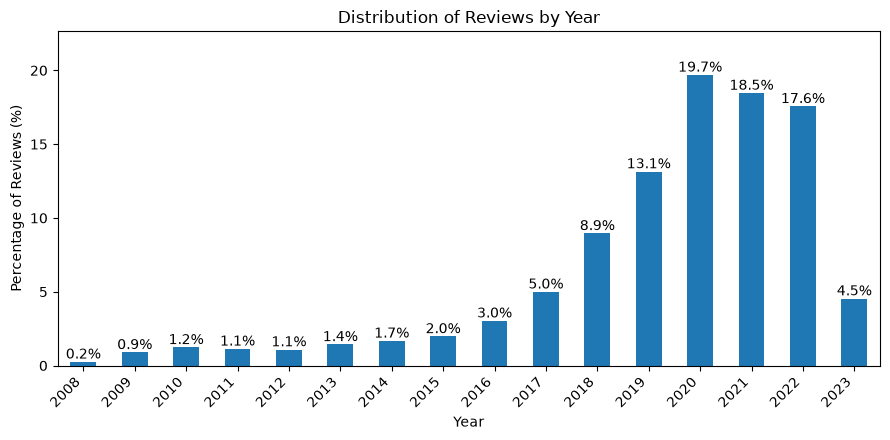

In [36]:
# Visualising percentage of reviews per year

reviews_per_year_pct.plot(kind='bar', figsize=(9, 4.5))

plt.xlabel('Year')
plt.ylabel('Percentage of Reviews (%)')
plt.title('Distribution of Reviews by Year')
plt.xticks(rotation=45, ha='right')
plt.ylim(0, reviews_per_year_pct.max() * 1.15)

for i, value in enumerate(reviews_per_year_pct):
    plt.text(i, value, f'{value:.1f}%', ha='center', va='bottom')

plt.tight_layout()
plt.show()

Reviews span 2008 - 2023, with review activity increasing substantially after 2018. The decline in 2023 reflects limited representation in the dataset. This suggests interactions are not uniformly distributed over time, and a temporal ordering should potentially be considered when selecting a validation strategy.

In [37]:
# Evalaute how repeated user-product interactions are spread over time

repeated = reviews[
    reviews.duplicated(
        subset=['author_id', 'product_id'], keep=False
    )
].sort_values(
    ['author_id', 'product_id', 'rating', 'submission_time']
)

repeated [
    ['author_id', 'product_id', 'rating', 'submission_time']
].head(20)

,author_id,product_id,rating,submission_time
238163,1000010050,P378852,5,2013-11-18
238151,1000010050,P378852,5,2013-12-08
1018025,10001768414,P429043,5,2018-08-29
1017974,10001768414,P429043,5,2019-12-16
347357,1000708145,P266126,5,2011-03-06
347317,1000708145,P266126,5,2011-03-31
980244,1000899606,P482269,1,2022-03-09
980174,1000899606,P482269,1,2022-03-15
332892,1001796334,P42205,5,2009-11-29
332373,1001796334,P42205,5,2011-01-12


The repeated user-product reviews for duplicated user-product pairs are separated in time (by month/years), which could support choosing the latest rating signal during the preprocessing. 

### 5.3. User Activity - Reviews per User
Evaluating how active are the users (low vs high engagement) and how much preference history exists per user.

In [38]:
# Check users activity distribution
reviews_per_user = reviews.groupby('author_id').size() 

reviews_per_user.describe().round(2)

count    503216.00
mean          2.17
std           3.41
min           1.00
25%           1.00
50%           1.00
75%           2.00
max         292.00
dtype: float64

In [39]:
# Zooming into high-end review threshold
reviews_per_user.describe(percentiles= [0.50, 0.75, 0.90, 0.95, 0.99, 0.995, 0.997, 0.999]).round(2)

count    503216.00
mean          2.17
std           3.41
min           1.00
50%           1.00
75%           2.00
90%           4.00
95%           6.00
99%          13.00
99.5%        20.00
99.7%        27.00
99.9%        48.00
max         292.00
dtype: float64

The user activity is highly right-skewed. Half of the users have only 1 review and 75% have no more than 2, while a small minority contribute substantially more reviews.

In [40]:
#Calculating the size of population with exactly one 1 review

reviews_per_user_one = (reviews_per_user == 1).mean() *100

print(f'Percentage of users with only one 1 review: {reviews_per_user_one:.2f}%')

Percentage of users with only one 1 review: 58.18%


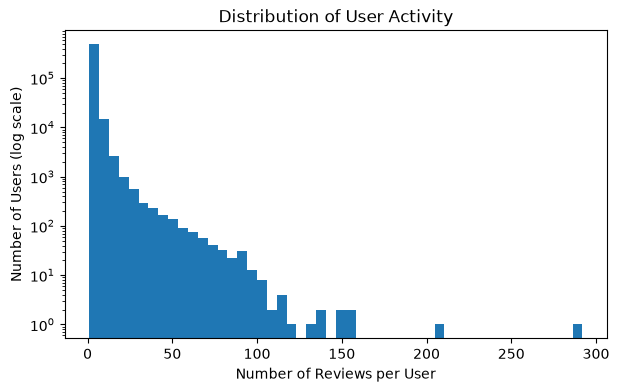

In [41]:
#Visualising distribution of user activity (log scale)

plt.figure(figsize=(7, 4))

plt.hist(reviews_per_user, bins=50)
plt.yscale('log')


plt.xlabel('Number of Reviews per User')
plt.ylabel('Number of Users (log scale)')
plt.title('Distribution of User Activity')
plt.show()

User activity is strongly right-skewed. 58% of the users contribute to only one review, and 75% to no more than 2 reviews. Above this range, the count rises rapidly to 292 reviews, showing a long tail of highly active users.

User activity is highly sparse, indicating that for most users, the dataset contains very limited historical preference information for the model to learn from. Whereas a minority of highly engaged users provide considerably more information.

### 5.4. Products Activity - Reviews per Product

Evaluating if reviews are evenly distributed across products and how much preferences do we have per product.

In [42]:
# Check product activity distribution

reviews_per_product = reviews.groupby('product_id').size() 

reviews_per_product.describe().round(2)

count     2351.00
mean       465.51
std        889.48
min          1.00
25%         37.00
50%        164.00
75%        488.50
max      16138.00
dtype: float64

In [43]:
# Zooming into review threshold
reviews_per_product.describe(percentiles= [0.25, 0.50, 0.75, 0.80, 0.90, 0.95, 0.99, 0.999]).round(2)

count     2351.00
mean       465.51
std        889.48
min          1.00
25%         37.00
50%        164.00
75%        488.50
80%        621.00
90%       1197.00
95%       1963.50
99%       4403.00
99.9%     7687.40
max      16138.00
dtype: float64

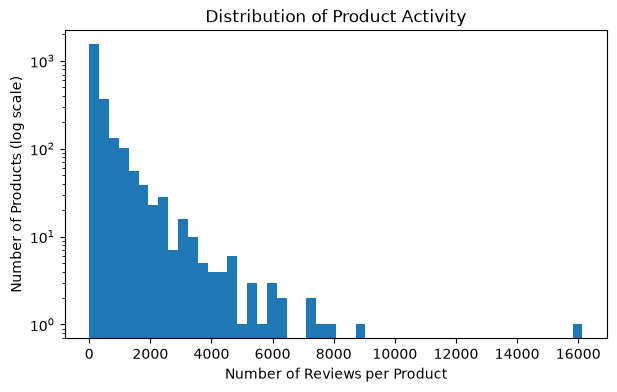

In [44]:
# Visualise distribution of product activities (log scale)

plt.figure(figsize=(7, 4))

plt.hist(reviews_per_product, bins=50)
plt.yscale('log')

plt.xlabel('Number of Reviews per Product')
plt.ylabel('Number of Products (log scale)')
plt.title('Distribution of Product Activity')
plt.show()

Product activity is strongly right-skewed, with half of the products receiving no more than 164 reviews, while a small proportion receiving several thousand, and the most-reviewed products exceeding 16,000 reviews. This indicates a substantial variation in the amount of rating information available across products.

### 5.5. User-Product Interaction Sparsity 
Assessing how much the overall user-product interactions is observed. 

In [45]:
# What is the percentage of the possible user-product matrix is observed. 

#Number of unique observed user_product interactions
unique_pairs = reviews[
    ['author_id', 'product_id']
].drop_duplicates().shape[0]

#Number of possible user-product interactions
n_users = reviews['author_id'].nunique()
n_products = reviews['product_id'].nunique()

possible_pairs = (n_users * n_products)

#Matrix density and sparsity
density_pct = unique_pairs / possible_pairs *100
sparcity_pct = 100 - density_pct

print(f'Unique user-product interactions: {unique_pairs:,}')
print(f'Possible user-product interactions: {possible_pairs:,}')
print(f'Density: {density_pct:.2f}%')
print(f'Sparsity: {sparcity_pct:.2f}%')

Unique user-product interactions: 1,088,886
Possible user-product interactions: 1,183,060,816
Density: 0.09%
Sparsity: 99.91%


The user-product interaction matrix is highly sparse, with only 0.09% of possible user-product pairs observed. This connects to the 58% of users with only one review, which helps explain the matrix sparsity. 

### 5.6. Product and Profile Attributes

* Product features: brand_name, price_usd
* Additional preference signal: is_recommended
* User profile features: skin_tone, skin_type, hair_color, eye_color

#### 5.6.1. Brands
Assessing brand distribution per user and whether users with multiple reviews tend to review multiple brands or stay with the same brand

In [46]:
# Brands variation per user
brands_per_user = (reviews.groupby('author_id')['brand_name'].nunique())

brands_per_user.describe(percentiles=[0.25, 0.50, 0.75, 0.90]).round(2)

count    503216.00
mean          1.63
std           1.84
min           1.00
25%           1.00
50%           1.00
75%           2.00
90%           3.00
max          67.00
Name: brand_name, dtype: float64

In [47]:
# Brands per user with 2+ reviews
brands_per_user[reviews_per_user >= 2].describe(percentiles=[0.25, 0.50, 0.75, 0.90]).round(2)

count    210468.00
mean          2.51
std           2.60
min           1.00
25%           1.00
50%           2.00
75%           3.00
90%           4.00
max          67.00
Name: brand_name, dtype: float64

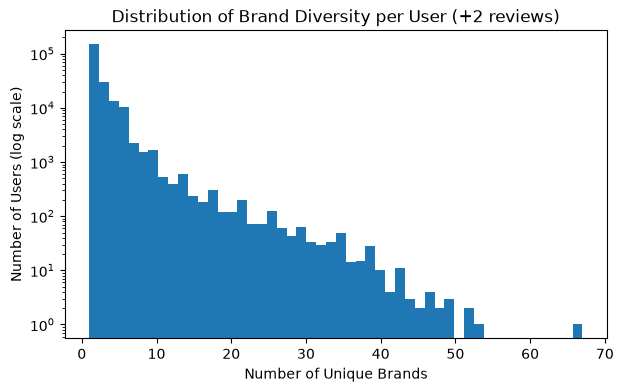

In [48]:
# Visualise number of brands per unique user (log scale)

plt.figure(figsize=(7, 4))

plt.hist(brands_per_user[reviews_per_user >= 2], bins=50)
plt.yscale('log')

plt.xlabel('Number of Unique Brands')
plt.ylabel('Number of Users (log scale)')
plt.title('Distribution of Brand Diversity per User (+2 reviews)')
plt.show()

Brand diversity is right-skewed. Users tend to review products associated with one brand, which is expected given the larger proportion of one-review users. However, among users with 2+ reviews, the median increases to 2 brands, with 90% reviewing no more than 4, and only a smaller share of users showing wider brand preferences.

### 5.6.2. Price

In [49]:
# Price distribution
reviews['price_usd'].describe(percentiles=[0.25, 0.50, 0.75, 0.90]).round(2)

count    1094411.00
mean          49.01
std           40.04
min            3.00
25%           25.00
50%           39.00
75%           62.00
90%           89.00
max         1900.00
Name: price_usd, dtype: float64

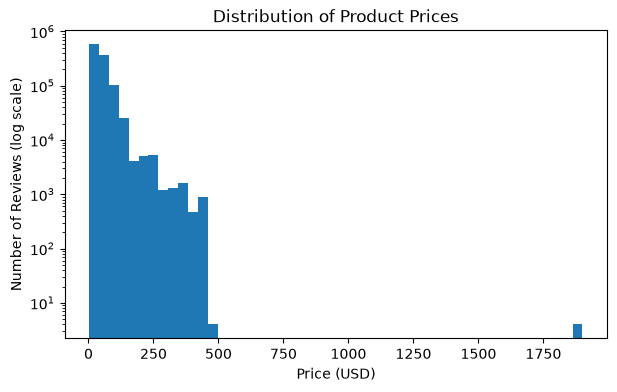

In [50]:
# Visualise price distribution (log scale)

plt.figure(figsize=(7, 4))

plt.hist(reviews['price_usd'], bins=50)
plt.yscale('log')

plt.xlabel('Price (USD)')
plt.ylabel('Number of Reviews (log scale)')
plt.title('Distribution of Product Prices')
plt.show()

In [51]:
# Price range per user with 2+ reviews
price_range_per_user = (
    reviews.groupby('author_id')['price_usd'].max()
    - reviews.groupby('author_id')['price_usd'].min()
)

price_range_per_user[reviews_per_user >= 2].describe(percentiles=[0.25, 0.50, 0.75, 0.90]).round(2)

count    210468.00
mean         48.74
std          56.06
min           0.00
25%          19.00
50%          32.50
75%          57.10
90%          96.00
max        1878.00
Name: price_usd, dtype: float64

In [52]:
# Price distribution per rating
reviews.groupby('rating')['price_usd'].median().round(2)

rating
1    38.0
2    38.0
3    39.0
4    41.0
5    39.0
Name: price_usd, dtype: float64

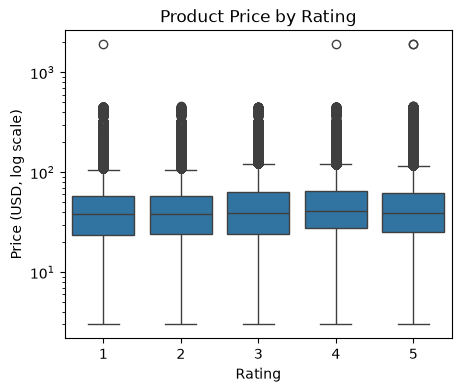

In [53]:
# Visualise Price vs Rating distribution

plt.figure(figsize=(5, 4))

sns.boxplot(
    x='rating',
    y='price_usd',
    data=reviews
)

plt.yscale('log')
plt.xlabel('Rating')
plt.ylabel('Price (USD, log scale)')
plt.title('Product Price by Rating')
plt.show()

Price is right-skewed, with most reviewed products in lower/moderate price ranges and a smaller number of more expensive products. Price ranges within users are right-skewed. Most users with 2+ reviews interact within lower/moderate price ranges, while smaller users share review product with substantially wider price ranges. Also, the median prices per rating level ($38-$41) suggest no clear association between product price and rating.

#### 5.6.3. Is_Recommended (recommended flag)

In [54]:
#Distribition of is_recommended

reviews['is_recommended'].value_counts(normalize=True, dropna=False).round(2)

is_recommended
1.0    0.71
NaN    0.15
0.0    0.14
Name: proportion, dtype: float64

In [55]:
#Recommended proportion withing each Rating
pd.crosstab(
    reviews['rating'],
    reviews['is_recommended'],
    normalize='index'
).round(2)

is_recommended,0.0,1.0
rating,,
1,0.99,0.01
2,0.96,0.04
3,0.64,0.36
4,0.03,0.97
5,0.00,1.00


71% if users recommended the product and 14% did not, while 15% had no opinion. For a 5-star rating, 100% of users selected recommended, while for a 4-star rating, 97% recommended and 3% did not. This relationship analysis indicates overlapping information between rating and is_recommended. This overlap suggests that is_recommended can be removed. 

#### 5.6.4. User profile features (skin_tone, skin_type, hair_color, eye_color)

In [56]:
# Skin type distribution
reviews['skin_type'].value_counts(normalize=True, dropna=False).round(2)

skin_type
combination    0.50
dry            0.17
normal         0.12
oily           0.11
NaN            0.10
Name: proportion, dtype: float64

In [57]:
# Skin tone distribution
reviews['skin_tone'].value_counts(normalize=True, dropna=False).round(2)

skin_tone
light          0.24
fair           0.19
lightMedium    0.18
NaN            0.16
medium         0.06
mediumTan      0.06
fairLight      0.05
tan            0.03
deep           0.02
rich           0.01
olive          0.00
porcelain      0.00
dark           0.00
notSureST      0.00
ebony          0.00
Name: proportion, dtype: float64

In [58]:
# Hair color distribution
reviews['hair_color'].value_counts(normalize=True, dropna=False).round(2)

hair_color
brown       0.37
NaN         0.21
blonde      0.19
black       0.17
auburn      0.03
red         0.02
brunette    0.01
gray        0.00
Name: proportion, dtype: float64

In [59]:
# Eye color distribution
reviews['eye_color'].value_counts(normalize=True, dropna=False).round(2)

eye_color
brown    0.43
NaN      0.19
blue     0.16
hazel    0.11
green    0.11
Grey     0.00
gray     0.00
Name: proportion, dtype: float64

In [60]:
# Assessing relationship between user profile features and rating
for col in ['skin_tone', 'skin_type', 'hair_color', 'eye_color']:
    print(f'\n{col}')
    print(reviews.groupby(col)['rating'].mean().round(2))


skin_tone
skin_tone
dark           4.27
deep           4.26
ebony          3.33
fair           4.27
fairLight      4.25
light          4.30
lightMedium    4.32
medium         4.33
mediumTan      4.28
notSureST      4.03
olive          4.26
porcelain      4.23
rich           4.31
tan            4.28
Name: rating, dtype: float64

skin_type
skin_type
combination    4.31
dry            4.29
normal         4.28
oily           4.27
Name: rating, dtype: float64

hair_color
hair_color
auburn      4.32
black       4.28
blonde      4.32
brown       4.29
brunette    4.23
gray        4.31
red         4.29
Name: rating, dtype: float64

eye_color
eye_color
Grey     4.14
blue     4.30
brown    4.30
gray     4.21
green    4.29
hazel    4.30
Name: rating, dtype: float64


Assessment of user profile features (skin_tone, skin_type, hair_color, eye_color) indicates no obvious differences in overall rating behaviours across these features. The average ratings are predominantly in 4.2-4.3 range across these groups. However this information does not tell about product popularity.

Also, given higher missingness of eye colour and hair color (~20%) I am considering to remove these 2 attributes and retain skin_tone information (potentially also skin_type).

In [61]:
# Remove obsolete features

reviews = reviews.drop(
    columns=['is_recommended', 'eye_color', 'hair_color']
)

In [62]:
reviews.columns

Index(['author_id', 'rating', 'submission_time', 'skin_tone', 'skin_type',
       'product_id', 'product_name', 'brand_name', 'price_usd'],
      dtype='str')

**EDA Findings and Implications:**

* **Limited interaction history:** The user–product matrix is 99.91% sparse, and 58% of users contribute only a single review. This severely limits the evidence available for personalisation and informs the evaluation eligibility.
* **Uneven activity:** User and product review counts are strongly right-skewed. This pattern suggests examining whether prediction error varies according to available user history.
* **High-rating concentration:** Most ratings are four or five stars, making the training-set mean a useful benchmark for assessing the benefit of personalisation.
* **Uneven temporal coverage:** Review activity varies over time, suggesting an evaluation that preserves the order of each user’s interactions. Along with repeated-pair checks, these findings inform subsequent cleaning, splitting, and feature-preparation decisions.

## 6. Experimental Design and Model Data Preparation

In his project I compare 3 selected models: **Biased Matrix Factorisation (BMF), Base Neural Collaborative Filtering (NCF) and Feature-aware NCF.** 
Additionally, their rating-prediction accuracy is also compared with a **global-mean baseline.** 
*NOTE: The model selection and architecture are presented in* **Section 7.**

### 6.1. Evaluating User Population and Eligibility

The sparse user histories identified in EDA motivated me to test the recommended temporal global split (Meng et al., 2020) but but almost 80% of test interactions involved users or products unseen during training. Therefore, I explored a temporal per user leave-last-out split which was described by the same authors. Following this approach, the latest interaction is reserved for testing, the second-latest for validation while all earlier interactions form the training set. 

The following eligibility thresholds were investigated to esnure that I have enough interaction history for the split:

* **1 review:** no history to learn from (insufficient for separate training and evaluation.)
* **2 reviews:** allows one training and one test interaction, no validation
* **3 reviews:** allows at least one interaction in each of the three sets.
* **4+ reviews:** provides more training history but excludes additional users.

In [63]:
#Count and percentage of users by minimum review history
for n in [1,2,3,4,5,10]:
    count = (reviews_per_user >= n).sum()
    pct = count / len(reviews_per_user) *100

    print(f'{n}+ reviews: {count:,} users ({pct:.2f}%)')

1+ reviews: 503,216 users (100.00%)
2+ reviews: 210,468 users (41.82%)
3+ reviews: 105,750 users (21.01%)
4+ reviews: 63,190 users (12.56%)
5+ reviews: 40,880 users (8.12%)
10+ reviews: 9,387 users (1.87%)


Around 21% of the ~503K users initially have at least 3 interactions, potentially supporting my chronological train–validation–test split. However, before confirming the eligibility, repeated user–product pairs must be resolved, as 24% of them contains differing ratings with different submission times.

In [64]:
#Checking the time span across the repeated reviews
repeated = reviews[reviews.duplicated(['author_id', 'product_id'], keep=False)].copy()

time_span = (
    repeated.groupby(['author_id', 'product_id'])['submission_time']
    .agg(['min', 'max'])
)

time_span['days_between'] = (time_span['max'] - time_span['min']).dt.days

time_span['days_between'].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90]
)

count    4953.000000
mean      242.798910
std       357.101177
min         0.000000
25%        11.000000
50%       101.000000
75%       337.000000
90%       668.800000
max      3666.000000
Name: days_between, dtype: float64

The gaps between repeated reviews have a median of 101 days and a mean of 242 days, showing that reviews often occur months apart. I retain the latest rating to represent the most recent observed preference, consistent with the temporal evaluation approach.

### 6.2. Interaction Dataset Preparation 

Retaining the latest review per user–product pair, recalculating counts and apply the >=3 interaction threshold.


In [65]:
# Sort reviews chronologically and resolving repeated temporal user-product pairs

reviews_sorted = reviews.sort_values('submission_time')

interactions = reviews_sorted.drop_duplicates(
    subset=['author_id', 'product_id'],
    keep='last'
).copy()

In [66]:
# Unique interactions per user
interactions_per_user = interactions.groupby('author_id').size()

# Check eligibility per user
for n in [1,2,3,4,5, 10]:
    count = (interactions_per_user >= n).sum()
    pct = count / len(interactions_per_user) * 100
    
    print(f'{n}+ interactions: {count:,} users ({pct:.2f}%)')

1+ interactions: 503,216 users (100.00%)
2+ interactions: 209,105 users (41.55%)
3+ interactions: 104,861 users (20.84%)
4+ interactions: 62,480 users (12.42%)
5+ interactions: 40,433 users (8.03%)
10+ interactions: 9,246 users (1.84%)


In [67]:
#Prepare eligible set with at least 3 reviews interactions per user

user_counts = interactions.groupby('author_id').size()

eligible_users = user_counts[user_counts >=3].index

interactions_filtered = interactions[interactions['author_id'].isin(eligible_users)
].copy()

print('Interactions:', len(interactions_filtered))
print('User:', interactions_filtered['author_id'].nunique())
print('Products:', interactions_filtered['product_id'].nunique())

Interactions: 586287
User: 104861
Products: 2309


After retaining the latest review for each user–product pair, users with at least three interactions are selected for the train–validation–test split (~21% of all users).

### 6.3. Applying per-user temporal leave-last-out split

* Latest interaction -> Test
* Second-latest interaction -> Validation
* All earlier interactions -> Training

In [68]:
# Sort each user's interactions chronologically
interactions_filtered = interactions_filtered.sort_values(
    ['author_id','submission_time', 'product_id']
).reset_index(drop=True)

# Rank interactions from most recent within each user
interactions_filtered['reverse_rank'] = (
    interactions_filtered
    .groupby('author_id')
    .cumcount(ascending=False)
)

# Apply per-user temporal leave-last-out split
 
# Most recent interaction for test
test = interactions_filtered[
    interactions_filtered['reverse_rank'] == 0
].copy()

# Second-most recent for validation
validation = interactions_filtered[
    interactions_filtered['reverse_rank'] == 1
].copy()

# All earlier interactions for training
train = interactions_filtered[
    interactions_filtered['reverse_rank'] >= 2
].copy()

#Checking the split
print('Train:', len(train))
print('Validation:', len(validation))
print('Test:', len(test))

print('\nUsers:')
print('Train:', train['author_id'].nunique())
print('Validation:', validation['author_id'].nunique())
print('Test:', test['author_id'].nunique())

Train: 376565
Validation: 104861
Test: 104861

Users:
Train: 104861
Validation: 104861
Test: 104861


### 6.4. Warm-Start Filtering
User eligibility already ensures that every evaluated user has training history. Next, I want to ensure that products available in validation and test interactions are also available in trainiung, if not these should be removed - supported by Cañamares, Castells and Moffat (2020) and Yuan and Hernandez (2023).
)

In [69]:
# Identify products present in the training set 

train_products = set(train['product_id'])

validation_unseen = ~validation['product_id'].isin(train_products)
test_unseen = ~test['product_id'].isin(train_products)

print(
    f'Validation unseen products:'
    f'{validation_unseen.sum()} ({validation_unseen.mean():.2%})'
)

print(
    f'Test unseen products:'
    f'{test_unseen.sum()} ({test_unseen.mean():.2%})'
)

Validation unseen products:99 (0.09%)
Test unseen products:489 (0.47%)


In [70]:
# Retain validation and test interactions only for products present in training

validation = validation[
    validation['product_id'].isin(train_products)
    ].copy()

test = test[
    test['product_id'].isin(train_products)
].copy()


In [71]:
# Remove temporary column used to assign interaction split
train = train.drop(columns='reverse_rank')
validation = validation.drop(columns='reverse_rank')
test = test.drop(columns='reverse_rank')

In [72]:
#Final split:
print('Train;', train.shape)
print('Validation:', validation.shape)
print('Test;', test.shape)

Train; (376565, 9)
Validation: (104762, 9)
Test; (104372, 9)


**Takeway:**
Each user’s latest interaction was assigned to test, the second-latest to validation, and all earlier interactions to training. Validation and test interactions involving products absent from training were removed to ensure warm-start evaluation. As a result, I removed 0.09% of validation interactions and 0.47% of test interactions.

### 6.5. Feature Engineering and Transformation

To provide additional context for my Feature-Aware NCF model, 3 additional features were calculated from training interactions only, keeping validation and test information out of these calculations. This prevents data leakage to validation/test (guided by Géron, 2022). 

* **user_interactions_count**: *Number of training interactions per user. It captures available user history and defines activity groups for subgroup analysis.*
* **product_mean_rating**: *Mean training rating per product. It captures its historical rating tendency.*
* **product_popularity**: *Number of training interactions per product. It measures how frequently it appears in the observed training data.*


In [73]:
# Creating Additional Features

#User-level features 
user_stats = train.groupby('author_id').agg(
    user_interaction_counts=('rating', 'size')
)

#Product-level Features
product_stats = train.groupby('product_id').agg(
    product_mean_rating = ('rating', 'mean'),
    product_popularity = ('rating', 'size')
)


### 6.6. Preprocessing and Model Data Construction
User and product IDs are converted into integer indices using mappings created from the training set. The same mappings are applied to validation and test data. These indices identify each user and product and rating serves as the prediction target. Additional features are prepared for Feature-aware NCF, with numerical transformations fitted on training data only.

In [74]:
# Create user and product mappings from training data
users_ids = train['author_id'].unique()
product_ids = train['product_id'].unique()

user_to_idx = {user_id: idx for idx, user_id in enumerate(users_ids)}
product_to_idx = {product_id: idx for idx, product_id in enumerate(product_ids)}

print('Encoded users:', len(user_to_idx))
print('Encoded products:', len(product_to_idx))


Encoded users: 104861
Encoded products: 2180


In [75]:
# Apply user and product mapping to train, validation and test sets.
for df in [train, validation, test]:
    df['user_idx'] = df['author_id'].map(user_to_idx)
    df['product_idx'] = df['product_id'].map(product_to_idx)

# Verify if no user and products IDs remain unmapped
for name, df in [
    ('Train', train), 
    ('Validation', validation),   
    ('Test', test) 
]:

    print(
        name, 
        'unmapped users:', df['user_idx'].isna().sum(),
        '| unmapped products:', df['product_idx'].isna().sum()

    )

Train unmapped users: 0 | unmapped products: 0
Validation unmapped users: 0 | unmapped products: 0
Test unmapped users: 0 | unmapped products: 0


In [76]:
#Prepared dataset fields and roles
print('Train;', train.shape)
print('Validation:', validation.shape)
print('Test;', test.shape)

Train; (376565, 11)
Validation: (104762, 11)
Test; (104372, 11)


In [77]:
train.columns

Index(['author_id', 'rating', 'submission_time', 'skin_tone', 'skin_type',
       'product_id', 'product_name', 'brand_name', 'price_usd', 'user_idx',
       'product_idx'],
      dtype='str')

**Prepared dataset fields and roles**

* **Shared model inputs:** user_idx, product_idx
* **Prediction target:** rating
* **Identifiers and temporal reference:** author_id, product_id, submission_time
* **Product information:** brand_name, price_usd
* **Additional Feature-aware NCF inputs:** brand_name, price_usd, user_interaction_counts, product_mean_rating, product_popularity
* **Diagnostic attribute:** skin_type, skin_tone, retained for subgroup auditing but not used as a model input.

## 7. Models Selection
The models selection was guided by literature and comparing increasing modelling complexity:


1. **Global Mean baseline:** Predicts the average training ratings for everyone and it provides a reference point and RMSE benchmark (Pedregosa et al., 2011) for classical and deep learning models to evaluate their performance. 

2. **Biased Matrix Factorisation (BMF)**: is a classical machine learning baseline using user and product embeddings through a dot product, global means, and user/product biases (Koren, Bell and Volinsky, 2009).

3. **Base Neural Collaborative Filtering (Base NCF):** Deep learning model that learns non-linear interactions between user and product embeddings via a neural network (He et al., 2017).

4. **Feature-aware NCF build on NCF + features:** It extends the base NCF approach with the five additional features prepared earlier, drawing on attribute-aware collaborative filtering (Chen et al., 2020).

These models were selected to compare classic matrix factorisation, non-linear interactions and additional features input, with the goal to assess whether added complexity can improve models rating accuracy and ranking quality.

### 7.1. Global-Mean Baseline

In [78]:
#Global mean baseline using training ratings

global_mean = train['rating'].mean()

global_mean_rmse = root_mean_squared_error(
    validation['rating'],
    [global_mean] * len(validation)
)

print(f'Training global mean: {global_mean:.4f}')
print(f'Global Mean Validation RMSE: {global_mean_rmse:.4f}')

Training global mean: 4.3937
Global Mean Validation RMSE: 1.1293


### 7.2. BMF and Base NCF: Shared Setup
All 3 models except of the global-mean are implemented in Pytorch for consistent comparison (Paszke et al., 2019).

Model development uses training and validation data only, including hyperparameter tuning, early stopping and the Feature-aware NCF comparison. The test set is reserved for final performance evaluation and subgroup analysis, after model selection is complete.

#### 7.2.1. Shared Data Pipeline
All models consume the same inputs `(user_idx, product_idx, rating)` that is provided by the same DataLoaders.
The user and product indices are model inputs while the rating is the target. This allows for a consistent model comparison. For example: i.e. (125, 47, 5.0): User 125 rates product 47 with 5 stars.

In [79]:
# Shared data pipeline: identical inputs for every model

n_users = len(user_to_idx)
n_products = len(product_to_idx)

batch_size = 1024       # training batch size
eval_batch_size = 8192  # for evaluation and prediction

# Preparing dataset for Pytorch
def make_dataset(df):
    return TensorDataset(
        torch.tensor(df['user_idx'].to_numpy(), dtype=torch.long),
        torch.tensor(df['product_idx'].to_numpy(), dtype=torch.long),
        torch.tensor(df['rating'].to_numpy(), dtype=torch.float32),
    )


train_dataset = make_dataset(train)
validation_dataset = make_dataset(validation)

# Creating 3 loaders for learning/optimisation, calculation of Train RMSE and Validation RMSE
def make_loaders(seed=42):
    generator = torch.Generator().manual_seed(seed)   
    
    train_loader = DataLoader(
        train_dataset, batch_size=batch_size, shuffle=True, generator=generator
    )

    train_eval_loader = DataLoader(train_dataset, batch_size=eval_batch_size, shuffle=False)
    validation_loader = DataLoader(validation_dataset, batch_size=eval_batch_size, shuffle=False)

    return train_loader, train_eval_loader, validation_loader


print(f'Users: {n_users:,} | Products: {n_products:,}')
print(f'Training rows: {len(train_dataset):,} | Validation rows: {len(validation_dataset):,}')

Users: 104,861 | Products: 2,180
Training rows: 376,565 | Validation rows: 104,762


#### 7.2.2. Model Architectures

**Biased MF:** Predicts ratings by combining the training-set global mean, user and product biases, and the dot product of user and product embeddings.

- Initial n_factors: 30
- User and product biases initialised to zero

The initial configuration was informed by the D2L matrix-factorisation example (Zhang et al., 2023)

**Base NCF:** Concatenates user and product embeddings and passes them through a multilayer perceptron to predict a rating directly.

- Initial embedding dimension: 64
- Hidden-layer sizes: 128 and 64
- Initial dropout: 0.0

Initial configuration informed by the Amazon Beauty example (Singh, Dwivedi and Gautam, 2026)

These initial configurations are subsequently tuned using validation RMSE.

In [80]:
# Biased Matrix Factorisation
class BiasedMF(nn.Module):
    def __init__(self, n_users, n_products, global_mean, n_factors=30):
        super().__init__()
        self.register_buffer('global_mean', torch.tensor(float(global_mean)))

        self.user_bias = nn.Embedding(n_users, 1)
        self.product_bias = nn.Embedding(n_products, 1)
        self.user_factors = nn.Embedding(n_users, n_factors)
        self.product_factors = nn.Embedding(n_products, n_factors)

        nn.init.zeros_(self.user_bias.weight)
        nn.init.zeros_(self.product_bias.weight)
        nn.init.normal_(self.user_factors.weight, mean=0.0, std=0.01)
        nn.init.normal_(self.product_factors.weight, mean=0.0, std=0.01)

    def forward(self, user_idx, product_idx):
        interaction = (
            self.user_factors(user_idx) * self.product_factors(product_idx)
        ).sum(dim=-1)

        return (
            self.global_mean
            + self.user_bias(user_idx).squeeze(-1)
            + self.product_bias(product_idx).squeeze(-1)
            + interaction
        )

In [81]:
# Base Neural Collaborative Filtering (MLP tower)
class BaseNCF(nn.Module):
    def __init__(self, n_users, n_products, emb_dim=64,
                 hidden_layers=(128, 64), dropout=0.0, side_dim=0):
        super().__init__()

        self.user_embedding = nn.Embedding(n_users, emb_dim)
        self.product_embedding = nn.Embedding(n_products, emb_dim)
        nn.init.normal_(self.user_embedding.weight, mean=0.0, std=0.01)
        nn.init.normal_(self.product_embedding.weight, mean=0.0, std=0.01)

        # side_dim stays 0 for Base NCF; used by the Feature-aware extension
        layers = []
        input_dim = 2 * emb_dim + side_dim
        for hidden_dim in hidden_layers:
            layers += [nn.Linear(input_dim, hidden_dim), nn.ReLU(), nn.Dropout(dropout)]
            input_dim = hidden_dim
        self.mlp = nn.Sequential(*layers)
        self.output = nn.Linear(input_dim, 1)

    def mlp_input(self, user_idx, product_idx):
        return torch.cat(
            [self.user_embedding(user_idx), self.product_embedding(product_idx)], dim=-1
        )

    def forward(self, user_idx, product_idx):
        hidden = self.mlp(self.mlp_input(user_idx, product_idx))
        return self.output(hidden).squeeze(-1)

In [82]:
# Model builders functions
def build_bmf(config):
    return BiasedMF(
        n_users, 
        n_products, 
        global_mean, 
        n_factors=config['n_factors'])


def build_base_ncf(config):
    return BaseNCF(
        n_users,
        n_products,
        emb_dim=config['emb_dim'],
        hidden_layers=config['hidden_layers'],
        dropout=config['dropout']
    )

#### 7.2.3. Shared Training and Evaluation Functions
All models use Adam optimisation and MSE loss. Training and validation RMSE are recorded after each epoch, while early stopping monitors validation RMSE, and the best validation weights are restored. The epoch log is displayed with 'verbose=True' and with 'verbose=False' suppressed during tuning.

In [83]:
# Shared training and evaluation functions for the models
max_epochs = 30      # Maximium number of training epochs
patience = 3         # Stops after 3 epochs if there is no validation improvement

#set random seed
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

#RMSE and create loaders
def compute_rmse(model, loader):
    model.eval()
    squared_error = 0.0
    count = 0
    with torch.no_grad():
        for users, products, ratings in loader:
            predictions = model(users, products)
            squared_error += (predictions.double() - ratings.double()).square().sum().item()
            count += ratings.numel()
    return math.sqrt(squared_error / count)

#For each epoch train_model on train data
def train_model(build_fn, config, max_epochs=max_epochs, patience=patience,
                seed=42, verbose=False):
    set_seed(seed)
    model = build_fn(config)
    train_loader, train_eval_loader, validation_loader = make_loaders(seed)

    #Adam controls how params are getting updated 
    #'config' allows for params adjustment per model
    optimizer = torch.optim.Adam(
        model.parameters(), lr=config['lr'], weight_decay=config['weight_decay']
    )
    #MSE gets minimise during the model training
    loss_function = nn.MSELoss()

    history = {'epoch': [], 'train_rmse': [], 'validation_rmse': []}
    best_rmse = float('inf')
    best_epoch = 0
    best_state = None
    epochs_without_improvement = 0

    for epoch in range(1, max_epochs + 1):
        model.train()
        for users, products, ratings in train_loader:
            optimizer.zero_grad()
            loss = loss_function(model(users, products), ratings)
            loss.backward()
            optimizer.step()

        # Train RMSE in eval mode for a comparison with validation
        train_rmse = compute_rmse(model, train_eval_loader)
        validation_rmse = compute_rmse(model, validation_loader)

        if not np.isfinite([train_rmse, validation_rmse]).all():
            raise RuntimeError('Non-finite RMSE detected. Check the learning rate.')

        history['epoch'].append(epoch)
        history['train_rmse'].append(train_rmse)
        history['validation_rmse'].append(validation_rmse)

        if verbose:
            print(f'Epoch {epoch:02d} | Train RMSE: {train_rmse:.4f} | '
                  f'Validation RMSE: {validation_rmse:.4f}')

        if validation_rmse < best_rmse:
            best_rmse = validation_rmse
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict()) #returning best valid epoch
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= patience:
                if verbose:
                    print(f'Early stopping at epoch {epoch:02d} '
                          f'(no improvement for {patience} epochs)')
                break
    else:
        if verbose:
            print(f'Reached maximum of {max_epochs} epochs')

    # Restore the best validation epoch
    model.load_state_dict(best_state)
    model.eval()

    if verbose:
        print(f'Best epoch: {best_epoch:02d} | Best Validation RMSE: {best_rmse:.4f}')

    return model, history, best_epoch, best_rmse

#### 7.2.4. Initial Training Runs
BMF and Base NCF are initially trained using the same learning rate and weight decay, providing a consistent starting point for comparison. Each model is subsequently tuned using validation RMSE.

In [84]:
# Biased MF initial baseline
bmf_initial_config = {'n_factors': 30, 'lr': 0.002, 'weight_decay': 1e-5}

bmf_model, bmf_history, bmf_best_epoch, bmf_best_rmse = train_model(
    build_bmf,
    bmf_initial_config,
    verbose=True
)

Epoch 01 | Train RMSE: 0.9281 | Validation RMSE: 1.0827
Epoch 02 | Train RMSE: 0.7552 | Validation RMSE: 1.0175
Epoch 03 | Train RMSE: 0.5963 | Validation RMSE: 0.9948
Epoch 04 | Train RMSE: 0.4784 | Validation RMSE: 0.9898
Epoch 05 | Train RMSE: 0.4015 | Validation RMSE: 0.9895
Epoch 06 | Train RMSE: 0.3511 | Validation RMSE: 0.9889
Epoch 07 | Train RMSE: 0.3147 | Validation RMSE: 0.9891
Epoch 08 | Train RMSE: 0.2870 | Validation RMSE: 0.9884
Epoch 09 | Train RMSE: 0.2662 | Validation RMSE: 0.9882
Epoch 10 | Train RMSE: 0.2517 | Validation RMSE: 0.9888
Epoch 11 | Train RMSE: 0.2423 | Validation RMSE: 0.9891
Epoch 12 | Train RMSE: 0.2358 | Validation RMSE: 0.9893
Early stopping at epoch 12 (no improvement for 3 epochs)
Best epoch: 09 | Best Validation RMSE: 0.9882


In [85]:
#Base NCF initial baseline
ncf_initial_config = {
    'emb_dim': 64,
    'hidden_layers': (128, 64),
    'dropout': 0.0,
    'lr': 0.002,
    'weight_decay': 1e-5
}

ncf_model, ncf_history, ncf_best_epoch, ncf_best_rmse = train_model(
    build_base_ncf,
    ncf_initial_config,
    verbose=True
)

Epoch 01 | Train RMSE: 0.8385 | Validation RMSE: 1.0507
Epoch 02 | Train RMSE: 0.7591 | Validation RMSE: 1.0378
Epoch 03 | Train RMSE: 0.7209 | Validation RMSE: 1.0712
Epoch 04 | Train RMSE: 0.6809 | Validation RMSE: 1.0795
Epoch 05 | Train RMSE: 0.6380 | Validation RMSE: 1.0898
Early stopping at epoch 05 (no improvement for 3 epochs)
Best epoch: 02 | Best Validation RMSE: 1.0378


**Initial Run Results:** BMF stopped after 9 epochs. Base NCF’s training RMSE continued to decrease, while validation RMSE got worse after only epoch 2, indicating early overfitting. Next stage is the paramaters tuning.

## 8. Hyperparameter Tuning: BMF and Base NCF
Hyperparameters are tuned sequentially, one at a time. Drawing on the roles of model capacity, optimisation and regularisation discussed in the literature (Goodfellow, Bengio and Courville, 2016; Smith, 2018), I chose to tune embedding dimension first to adjust model capacity, learning rate to control training updates, then weight decay and dropout to limit overfitting.  At each stage, candidate values is tested while other settings are fixed. The value that achieves the lowest validation RMSE is retained for the next tuning stage. Test data is not used.

**NOTE**: BMF’s validation RMSE was still improving at the 30-epoch limit, so I increased the maximum to 50 epochs while retaining early stopping. The best validation result was reached at epoch 43.

In [86]:
# Sequential one-at-a-time tuning
def sequential_tune(model_name, build_fn, base_config, stages, max_epochs=30):
    config = dict(base_config)
    results = []
    cache = {}  # avoids retraining a configuration already evaluated in an earlier stage

    for param, values in stages:
        stage_scores = {}
        for value in values:
            trial = {**config, param: value} # changes only the evaluated parameter, the rest is fixed
            key = tuple(sorted(trial.items()))
            if key not in cache: 
                _, _, best_epoch, best_rmse = train_model(build_fn, trial, max_epochs=max_epochs, verbose=False)
                cache[key] = (best_rmse, best_epoch) 
            best_rmse, best_epoch = cache[key]

            stage_scores[value] = best_rmse
            results.append({
                'model': model_name, 'stage': param, 'value': value,
                'val_rmse': best_rmse, 'best_epoch': best_epoch,
            })

        config[param] = min(stage_scores, key=stage_scores.get) # selects a candidate with the lowest Val RMSE, carries to the next tuning stage
        print(f'{model_name} | {param}: selected {config[param]} '
              f'(Validation RMSE {stage_scores[config[param]]:.4f})')

    return config, pd.DataFrame(results)

In [87]:
# Biased MF tuning
bmf_base_config = {'n_factors': 30, 'lr': 0.002, 'weight_decay': 1e-5}
bmf_stages = [
    ('n_factors', [10, 30, 50, 70, 90]),
    ('lr', [1e-3, 2e-3, 5e-3]),
    ('weight_decay', [1e-6, 1e-5, 1e-4]),    
]

bmf_config, bmf_tuning = sequential_tune('Biased MF', build_bmf,bmf_base_config, bmf_stages, max_epochs=50
)

Biased MF | n_factors: selected 90 (Validation RMSE 0.9806)
Biased MF | lr: selected 0.001 (Validation RMSE 0.9767)
Biased MF | weight_decay: selected 1e-06 (Validation RMSE 0.9726)


In [88]:
# Base NCF tuning
ncf_base_config = {'emb_dim': 64,'hidden_layers': (128, 64),'dropout': 0.0,'lr': 2e-3,'weight_decay': 1e-5
}
ncf_stages = [
    ('emb_dim', [32, 64, 96]),
    ('lr', [1e-3, 2e-3, 5e-3]),
    ('weight_decay', [1e-6, 1e-5, 1e-4]),
    ('dropout', [0.0, 0.1, 0.2, 0.3]),
]

ncf_config, ncf_tuning = sequential_tune('Base NCF', build_base_ncf, ncf_base_config, ncf_stages)

Base NCF | emb_dim: selected 96 (Validation RMSE 1.0368)
Base NCF | lr: selected 0.002 (Validation RMSE 1.0368)
Base NCF | weight_decay: selected 0.0001 (Validation RMSE 1.0328)
Base NCF | dropout: selected 0.0 (Validation RMSE 1.0328)


In [89]:
# Tuning results
tuning_results = pd.concat([bmf_tuning, ncf_tuning], ignore_index=True)
tuning_results.round({'val_rmse': 4})

,model,stage,value,val_rmse,best_epoch
0,Biased MF,n_factors,10.000000,0.9991,5
1,Biased MF,n_factors,30.000000,0.9882,9
2,Biased MF,n_factors,50.000000,0.9839,8
3,Biased MF,n_factors,70.000000,0.9830,9
4,Biased MF,n_factors,90.000000,0.9806,28
5,Biased MF,lr,0.001000,0.9767,11
6,Biased MF,lr,0.002000,0.9806,28
7,Biased MF,lr,0.005000,0.9858,17
8,Biased MF,weight_decay,0.000001,0.9726,43
9,Biased MF,weight_decay,0.000010,0.9767,11


**Results:** BMF benefited from a longer training, extending the epoch run from 30 to 50 epochs allowed the selected configuration to reach its best validation at epoch 43 while Base NCF achieved its best results as epoch 2 indicating that tuning did not resolve the early overfitting challenge.

## 9. Final Training (BMF and Base NCF)
Each model is retrained once with its selected configuration and seed 42. Validation RMSE guides early stopping, and the weights from the best validation epoch are restored. The epoch logs and selected epochs are reported below.

In [90]:
# Final Biased MF - extended epoch 
print('Biased MF', bmf_config)
bmf_model, bmf_history, bmf_best_epoch, bmf_val_rmse = train_model(
    build_bmf, bmf_config, max_epochs=50, patience=3, verbose=True
)

Biased MF {'n_factors': 90, 'lr': 0.001, 'weight_decay': 1e-06}
Epoch 01 | Train RMSE: 0.9485 | Validation RMSE: 1.0942
Epoch 02 | Train RMSE: 0.7432 | Validation RMSE: 1.0290
Epoch 03 | Train RMSE: 0.5473 | Validation RMSE: 0.9991
Epoch 04 | Train RMSE: 0.4113 | Validation RMSE: 0.9877
Epoch 05 | Train RMSE: 0.3197 | Validation RMSE: 0.9842
Epoch 06 | Train RMSE: 0.2578 | Validation RMSE: 0.9813
Epoch 07 | Train RMSE: 0.2115 | Validation RMSE: 0.9798
Epoch 08 | Train RMSE: 0.1774 | Validation RMSE: 0.9786
Epoch 09 | Train RMSE: 0.1572 | Validation RMSE: 0.9779
Epoch 10 | Train RMSE: 0.1463 | Validation RMSE: 0.9780
Epoch 11 | Train RMSE: 0.1438 | Validation RMSE: 0.9777
Epoch 12 | Train RMSE: 0.1413 | Validation RMSE: 0.9782
Epoch 13 | Train RMSE: 0.1407 | Validation RMSE: 0.9773
Epoch 14 | Train RMSE: 0.1360 | Validation RMSE: 0.9777
Epoch 15 | Train RMSE: 0.1331 | Validation RMSE: 0.9765
Epoch 16 | Train RMSE: 0.1296 | Validation RMSE: 0.9768
Epoch 17 | Train RMSE: 0.1293 | Validati

In [91]:
# Final Base NCF
print('Base NCF', ncf_config)
base_ncf_model, base_ncf_history, base_ncf_best_epoch, base_ncf_val_rmse = train_model(
    build_base_ncf, ncf_config, verbose=True
)

Base NCF {'emb_dim': 96, 'hidden_layers': (128, 64), 'dropout': 0.0, 'lr': 0.002, 'weight_decay': 0.0001}
Epoch 01 | Train RMSE: 0.8470 | Validation RMSE: 1.0559
Epoch 02 | Train RMSE: 0.7903 | Validation RMSE: 1.0328
Epoch 03 | Train RMSE: 0.7471 | Validation RMSE: 1.0360
Epoch 04 | Train RMSE: 0.7125 | Validation RMSE: 1.0560
Epoch 05 | Train RMSE: 0.6824 | Validation RMSE: 1.0616
Early stopping at epoch 05 (no improvement for 3 epochs)
Best epoch: 02 | Best Validation RMSE: 1.0328


In [92]:
# Selected configurations and final validation results

selected_configs = pd.DataFrame([
    {'model': 'Biased MF', **bmf_config,'best_epoch': bmf_best_epoch,'val_rmse': bmf_val_rmse
    },

    {'model': 'Base NCF', **ncf_config, 'best_epoch': base_ncf_best_epoch,'val_rmse': base_ncf_val_rmse
}
]).set_index('model')

selected_configs.round({'val_rmse': 4})

,n_factors,lr,weight_decay,best_epoch,val_rmse,emb_dim,hidden_layers,dropout
model,,,,,,,,
Biased MF,90.0,0.001,0.000001,43,0.9726,NaN,NaN,NaN
Base NCF,NaN,0.002,0.000100,2,1.0328,96.0,"(128, 64)",0.0


The best validation weights are retained for evaluation and the selected Base NCF configuration provides the starting point for the feature-aware model.

## 10. Feature-aware NCF

Feature-aware NCF reuses the selected Base NCF hyperparameters and augments the model with additional existing and engineered features derived from the training data only:

* price_usd, user_interaction_counts, product_popularity *(log1p transformed to address skewness and standardised)*
* product_mean_rating *(standardised)*
* brand_name, uses brand embedding *(conservative decision, 8 fixed dimensions to learn brand-specific patterns and limit model capacity)* 

**NOTE:** Feature-aware NCF was tuned separately due to its instant overfitting, so performance differences reflect both the additional features and the changed hyperparameters. 

#### 10.1. Feature Preparation

In [93]:
# Side-feature preparation using training data only

def standardise(values):
    values = np.asarray(values, dtype=np.float32)
    return (values - values.mean()) / values.std()


# Product-level features, indexed by product_idx
product_features = (
    train.groupby('product_idx')
    .agg(
        brand_name=('brand_name', 'first'),
        price_usd=('price_usd', 'median')
    )
    .join(product_stats.rename(index=product_to_idx))
    .reindex(range(n_products))
)

# Encode brand
brand_to_idx = {
    brand: idx
    for idx, brand in enumerate(sorted(product_features['brand_name'].unique()))
}
n_brands = len(brand_to_idx)

product_brand_idx = torch.tensor(
    product_features['brand_name'].map(brand_to_idx).to_numpy(),
    dtype=torch.long
)

# Prepare numeric product features:
# price, mean rating, popularity
product_numeric = torch.tensor(
    np.column_stack([
        standardise(np.log1p(product_features['price_usd'])),
        standardise(product_features['product_mean_rating']),
        standardise(np.log1p(product_features['product_popularity']))
    ]),
    dtype=torch.float32
)

# User-level feature, indexed by user_idx
user_features = (
    user_stats
    .rename(index=user_to_idx)
    .reindex(range(n_users))
)

# Prepare user interaction count
user_numeric = torch.tensor(
    standardise(
        np.log1p(user_features['user_interaction_counts'])
    ).reshape(-1, 1),
    dtype=torch.float32
)

# Check that feature preparation produced no missing values
assert not product_features.isna().any().any(), 'Missing product features'
assert not user_features.isna().any().any(), 'Missing user features'

print(
    f'Brands: {n_brands} | '
    f'Product numeric: {product_numeric.shape} | '
    f'User numeric: {user_numeric.shape}'
)

Brands: 141 | Product numeric: torch.Size([2180, 3]) | User numeric: torch.Size([104861, 1])


### 10.2. Model Architecture

In [94]:
# Feature-aware NCF: Base NCF architecture expandeed with additional features

class FeatureAwareNCF(BaseNCF):
    def __init__(
        self,
        n_users,
        n_products,
        product_brand_idx,
        product_numeric,
        user_numeric,
        n_brands,
        brand_dim=8,
        emb_dim=64,
        hidden_layers=(128, 64),
        dropout=0.0
    ):
        side_dim = (
            brand_dim
            + product_numeric.shape[1]
            + user_numeric.shape[1]
        )

        super().__init__(
            n_users,
            n_products,
            emb_dim=emb_dim,
            hidden_layers=hidden_layers,
            dropout=dropout,
            side_dim=side_dim
        )

        self.register_buffer('product_brand_idx', product_brand_idx)
        self.register_buffer('product_numeric', product_numeric)
        self.register_buffer('user_numeric', user_numeric)

        self.brand_embedding = nn.Embedding(n_brands, brand_dim)

        nn.init.normal_(
            self.brand_embedding.weight, mean=0.0, std=0.01)

    def mlp_input(self, user_idx, product_idx):
        return torch.cat([
            super().mlp_input(user_idx, product_idx),
            self.brand_embedding(self.product_brand_idx[product_idx]),
            self.product_numeric[product_idx],
            self.user_numeric[user_idx],
        ], dim=-1)


def build_feature_ncf(config):
    return FeatureAwareNCF(
        n_users=n_users,
        n_products=n_products,
        product_brand_idx=product_brand_idx,
        product_numeric=product_numeric,
        user_numeric=user_numeric,
        n_brands=n_brands,
        emb_dim=config['emb_dim'],
        hidden_layers=config['hidden_layers'],
        dropout=config['dropout']
    )

# Reuse Base NCF selected hyperparameters

print('Feature-aware NCF', ncf_config)

fa_ncf_model, fa_ncf_history, fa_ncf_best_epoch, fa_ncf_val_rmse = train_model(
    build_feature_ncf,
    ncf_config,
    verbose=True
)

Feature-aware NCF {'emb_dim': 96, 'hidden_layers': (128, 64), 'dropout': 0.0, 'lr': 0.002, 'weight_decay': 0.0001}
Epoch 01 | Train RMSE: 0.8507 | Validation RMSE: 1.0603
Epoch 02 | Train RMSE: 0.7791 | Validation RMSE: 1.2534
Epoch 03 | Train RMSE: 0.7215 | Validation RMSE: 1.2024
Epoch 04 | Train RMSE: 0.6930 | Validation RMSE: 1.1933
Early stopping at epoch 04 (no improvement for 3 epochs)
Best epoch: 01 | Best Validation RMSE: 1.0603


### 10.3. Hyperparameters Tuning and Final Training
Given that the model is stopping already after the first epoch it signals overfitting. This mean that model learns fast but it generalises poorly. With this in mind I am finetuning the model separately starting with the Base NCF configuration, and keeping the embeddings constant and only adapting learning rate for even more granular updates, and regularisation and weight decay to reduce overfitting.

In [95]:
# Refinement due to rapid overfitting
fa_refine_base_config = {**ncf_config, 'emb_dim': 96}  
fa_refine_stages = [
    ('lr', [2e-4, 5e-4, 1e-3, 2e-3]),
    ('weight_decay', [1e-4, 5e-4, 1e-3]),
    ('dropout', [0.0, 0.1, 0.2, 0.3]),
]
fa_refined_config, fa_refine_tuning = sequential_tune(
    'Feature-aware NCF', build_feature_ncf,
    fa_refine_base_config, fa_refine_stages, max_epochs=50
)

Feature-aware NCF | lr: selected 0.0002 (Validation RMSE 1.0593)
Feature-aware NCF | weight_decay: selected 0.001 (Validation RMSE 1.0480)
Feature-aware NCF | dropout: selected 0.0 (Validation RMSE 1.0480)


In [96]:
#Training Feature-aware NCF model
print('Feature-aware NCF', fa_refined_config)

fa_ncf_refined_model, fa_ncf_refined_history, fa_ncf_refined_best_epoch, fa_ncf_refined_val_rmse = train_model(
    build_feature_ncf, fa_refined_config, max_epochs=30, verbose=True
)

Feature-aware NCF {'emb_dim': 96, 'hidden_layers': (128, 64), 'dropout': 0.0, 'lr': 0.0002, 'weight_decay': 0.001}
Epoch 01 | Train RMSE: 0.9707 | Validation RMSE: 1.1469
Epoch 02 | Train RMSE: 0.8242 | Validation RMSE: 1.0562
Epoch 03 | Train RMSE: 0.7818 | Validation RMSE: 1.0480
Epoch 04 | Train RMSE: 0.7633 | Validation RMSE: 1.0522
Epoch 05 | Train RMSE: 0.7507 | Validation RMSE: 1.0650
Epoch 06 | Train RMSE: 0.7433 | Validation RMSE: 1.0717
Early stopping at epoch 06 (no improvement for 3 epochs)
Best epoch: 03 | Best Validation RMSE: 1.0480


### 10.4. Validation Comparison with Base NCF
This comparison evaluates Base NCF and Feature-aware NCF. The differences in the Validation performance reflect both the additional features and the selected training configurations.

In [97]:
# Base NCF vs Feature-aware NCF

feature_comparison = pd.DataFrame({
    'Model': ['Base NCF', 'Feature-aware NCF'],
    'Validation RMSE': [
        base_ncf_val_rmse,
        fa_ncf_refined_val_rmse
    ],
    'Best epoch': [
        base_ncf_best_epoch,
        fa_ncf_refined_best_epoch
    ]
})

feature_comparison.round(4)

,Model,Validation RMSE,Best epoch
0,Base NCF,1.0328,2
1,Feature-aware NCF,1.0480,3


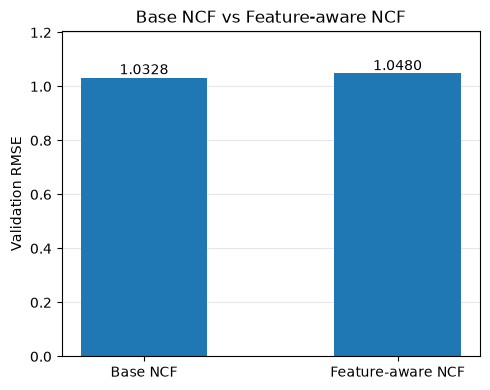

In [98]:
# Visualising Base NCF vs Feature-aware NCF

fig, ax = plt.subplots(figsize=(5, 4))

bars = ax.bar(
    feature_comparison['Model'],
    feature_comparison['Validation RMSE'],
    width=0.5,
)

for bar, rmse in zip(bars, feature_comparison['Validation RMSE']):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        rmse,
        f'{rmse:.4f}',
        ha='center',
        va='bottom'
    )

ax.set_ylim(0, feature_comparison['Validation RMSE'].max() * 1.15)
ax.set_ylabel('Validation RMSE')
ax.set_title('Base NCF vs Feature-aware NCF')
ax.set_axisbelow(True)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

**Results:** Feature aware NCF did not improve the prediction. The Base NCF has a marginally better performance.

## 11. Training and Validation Behaviour Across All Models
Visual summary of the per-epoch Train and Validation RMSE from the final model runs.

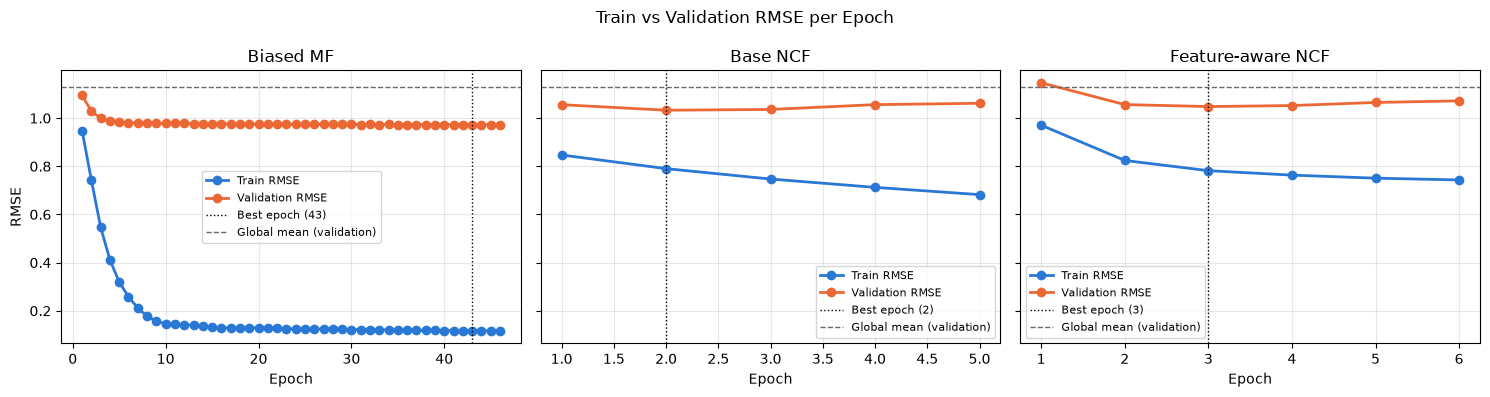

In [99]:
# Visualise Train versus Validation RMSE comparison
final_runs = [
    ('Biased MF', bmf_history, bmf_best_epoch),
    ('Base NCF', base_ncf_history, base_ncf_best_epoch),
    ('Feature-aware NCF', fa_ncf_refined_history, fa_ncf_refined_best_epoch),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for ax, (model_name, history, best_epoch) in zip(axes, final_runs):
    ax.plot(history['epoch'], history['train_rmse'], marker='o', linewidth=2,
            color='#2a78d6', label='Train RMSE')
    ax.plot(history['epoch'], history['validation_rmse'], marker='o', linewidth=2,
            color='#eb6834', label='Validation RMSE')
    ax.axvline(best_epoch, color='black', linestyle=':', linewidth=1,
               label=f'Best epoch ({best_epoch})')
    ax.axhline(global_mean_rmse, color="#6B6A6A", linestyle='--',
               linewidth=1, label='Global mean (validation)')
    ax.set_title(model_name)
    ax.set_xlabel('Epoch')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

axes[0].set_ylabel('RMSE')
fig.suptitle('Train vs Validation RMSE per Epoch')
plt.tight_layout()
plt.show()

**Results**: 
Validation RMSE shows how well all my models predict interactions they did not learn from during the initial training phase. 
BMF has visibly the longest training (best epoch 43) and the largest gap between train-validation. Training RMSE decreases rapidly at first, then flattens out. Validation RMSE remains relatively stable, with its lowest value at epoch 43, suggesting that there is only a small improvement from longer training. Both NCF models, on the other hand, reach their best validation performance early, at epochs 2 and 3. Then validation slightly rises error while training error falls confirming earlier observed overfitting.

## 12. Final Model Comparison on the Test Set

### 12.1. Rating Prediction Accuracy: Test RMSE
Comparing rating error across all test interactions.

In [100]:
# Calculate overall test RMSE for each models
test_dataset = make_dataset(test)
test_loader = DataLoader(test_dataset, batch_size=eval_batch_size, shuffle=False)

final_models = {
    'Biased MF': bmf_model,
    'Base NCF': base_ncf_model,
    'Feature-aware NCF': fa_ncf_refined_model,
}

test_rmse = {
    'Global Mean': root_mean_squared_error(test['rating'], np.full(len(test), global_mean))
}
for model_name, model in final_models.items():
    test_rmse[model_name] = compute_rmse(model, test_loader)

for model_name, rmse in test_rmse.items():
    print(f'{model_name:<18} Test RMSE: {rmse:.4f}')

Global Mean        Test RMSE: 1.1741
Biased MF          Test RMSE: 1.0884
Base NCF           Test RMSE: 1.1133
Feature-aware NCF  Test RMSE: 1.1329


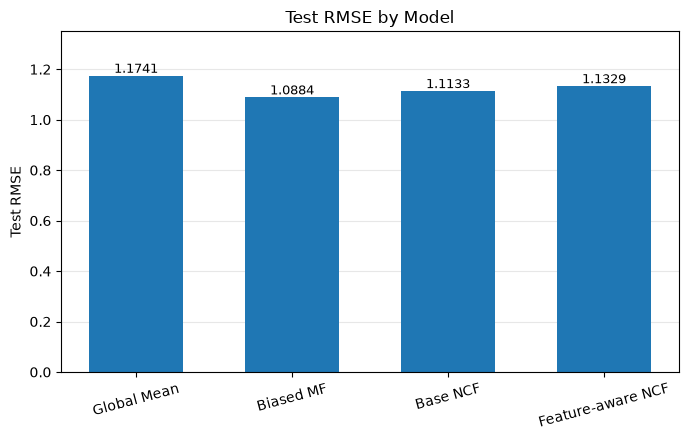

In [101]:
# Vidualise Test RMSE for each model

model_names = list(test_rmse.keys())
rmse_values = list(test_rmse.values())

fig, ax = plt.subplots(figsize=(7, 4.5))

bars = ax.bar(
    model_names,
    rmse_values,
    width=0.6
)

for bar, value in zip(bars, rmse_values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f'{value:.4f}',
        ha='center',
        va='bottom',
        fontsize=9
    )

ax.set_ylim(0, max(rmse_values) * 1.15)
ax.set_ylabel('Test RMSE')
ax.set_title('Test RMSE by Model')
ax.tick_params(axis='x', rotation=15)
ax.set_axisbelow(True)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

**Results:** All 3 models outperformed the global baseline (RMSE = 1.1741). Biased MF achieved the lowest Test RMSE (1.0884), followed by Base NCF (1.1133). Feature-aware NCF achieved a test RMSE of 1.1329, higher than the other models, indicating that the additional context did not improve rating prediction in this setup.

### 12.2 Ranking Quality: Sampled Test NDCG@10

Normalised Discounted Cumulative Gain(NDCG) evaluates ranking quality (Harris et al., 2020). NDCG metric was evaluated using a set of 100 products per user:

* **1 held-out product (rating >= 4) that the user rates in the test set**
* **99 unseen randomly sampled products the user has not rated (*negatives*)**

The model predicts a score for 100 products and ranks them accordingly. 
NDCG@10 looks at the top 10 recommendations and measures whether the test product appears near these 10 positions, with the 1st position rewarding a score of 1 and, if outside the top 10, it gives a score of 0. This sampled approach follows the Amazon Beauty Case approach (Ghosh et al., 2026) with similar data characteristics.

**Important:** According to He et al.(2017) unseen products do not mean irrelevant products, as the user may have purchased them, (dis)liked them, but simply did not rate them. In this dataset the relevance evidence to the user is not specified.

A fixed random seed was applied to ensure results across all models are reproducible.

In [102]:
# NDCG@10 evaluation setup

K = 10
n_negatives = 99

# Relevant held-out test interactions
ndcg_eval = test[test['rating'] >= 4].copy()

# Products previously seen by each user in train + validation
history = pd.concat([
    train[['user_idx', 'product_idx']],
    validation[['user_idx', 'product_idx']]
])

seen_products = (
    history.groupby('user_idx')['product_idx']
    .apply(set)
    .to_dict()
)

print('Users evaluated:', len(ndcg_eval))

Users evaluated: 83489


In [103]:
# Sample 99 unseen products per user

rng = np.random.default_rng(42)
sampled_candidates = {}

for _, row in ndcg_eval.iterrows():

    user = int(row['user_idx'])
    target = int(row['product_idx'])

    seen = seen_products.get(user, set())
    excluded = set(seen) | {target}

    available_negatives = np.array([
        p for p in range(n_products)
        if p not in excluded
    ])

    negatives = rng.choice(
        available_negatives,
        size=n_negatives,
        replace=False
    )

    sampled_candidates[user] = np.concatenate(
        ([target], negatives)
    )

In [104]:
print('Users:', len(sampled_candidates))
print('Candidates per user:', len(next(iter(sampled_candidates.values()))))

Users: 83489
Candidates per user: 100


In [105]:
#Calculating sampled NDCG@10 

def sampled_ndcg_at_k(model, k=K):
    model.eval()
    ndcg_scores = []

    with torch.no_grad():

        for _, row in ndcg_eval.iterrows():

            user = int(row['user_idx'])
            target = int(row['product_idx'])

            candidates = sampled_candidates[user]

            users = torch.full(
                (len(candidates),),
                user,
                dtype=torch.long
            )

            products = torch.tensor(
                candidates,
                dtype=torch.long
            )

            scores = model(users, products)

            # Target is first in candidate set
            target_score = scores[0]

            rank = int(
                (scores > target_score).sum().item()
            ) + 1

            if rank <= k:
                ndcg_scores.append(
                    1 / np.log2(rank + 1)
                )
            else:
                ndcg_scores.append(0.0)

    return np.mean(ndcg_scores)

In [106]:
# Calculate and store one sampled NDCG@10 per final model
sampled_test_ndcg = {}

for model_name, model in final_models.items():
    ndcg = sampled_ndcg_at_k(model)
    sampled_test_ndcg[model_name] = ndcg

    print(
        f'{model_name} Sampled Test NDCG@{K}: '
        f'{ndcg:.4f}'
    )

Biased MF Sampled Test NDCG@10: 0.0748
Base NCF Sampled Test NDCG@10: 0.0701
Feature-aware NCF Sampled Test NDCG@10: 0.0803


**Adding Random Ranking as a reference baseline.** The products are ordered randomly using the same 100-candidate set protocol as other models. The relevant test product has an equal chance of appearing at any of the 100 positions, and NDCG@10 is then averaged over all 100 positions. This comparison across all models will tell us if model-learned rankings improve the chance.  

In [107]:
# Random ranking baseline for 100 candidates

n_candidates = n_negatives + 1

random_ndcg = np.mean([
    1 / np.log2(rank + 1) if rank <= K else 0
    for rank in range(1, n_candidates + 1)
])

print(f'Random ranking NDCG@{K}: {random_ndcg:.4f}')

Random ranking NDCG@10: 0.0454


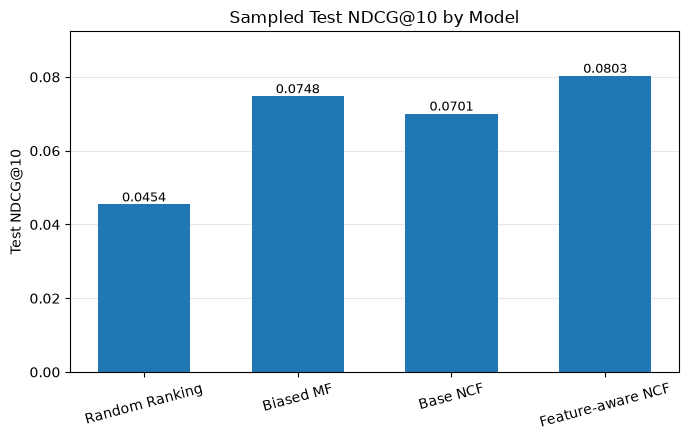

In [108]:
# Visualising Sampled Test NDCG@10 across models including reference baseline

model_names = ['Random Ranking'] + list(sampled_test_ndcg.keys())
ndcg_values = [random_ndcg] + list(sampled_test_ndcg.values())

fig, ax = plt.subplots(figsize=(7, 4.5))

bars = ax.bar(
    model_names,
    ndcg_values,
    width=0.6
)

for bar, value in zip(bars, ndcg_values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f'{value:.4f}',
        ha='center',
        va='bottom',
        fontsize=9
    )

ax.set_ylim(0, max(ndcg_values) * 1.15)
ax.set_ylabel(f'Test NDCG@{K}')
ax.set_title(f'Sampled Test NDCG@{K} by Model')
ax.tick_params(axis='x', rotation=15)
ax.set_axisbelow(True)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

**Results:**
Feature-aware NCF achieved the highest NDCG@10 (0.0803), followed by Base NCF (0.0748), while Base NCF achieved lower ranking performance (0.0701). All models performed above the reference baseline (0.0454). Although the absolute scores are modest, the results indicate that additional context supports ranking quality.

## 13. Explainability: Feature-aware NCF

To understand what drives my Feature-aware NCF model's predictions, I applied the SHAP technique with SHAP Deep Explainer (SHAP, n.d.-b), which estimates contributions to predicted ratings, but does not explain causal effect (Molnar, 2023). These contributions are summarised for 7 model input groups *(user and product embeddings, brand, price, product mean rating, product popularity and user activity)*. The results are evaluated based on the global and local importance (SHAP, n.d.-a):

* **Global Importance:** shows how strongly each input group contributes to the predicted rating, on average, across the explained validation observations.

* **Local Importance:** shows how individual contributions push the prediction above or below the background-reference prediction, with positive contributions increasing the predicted rating and negative ones decreasing it.

In [109]:
# SHAP setup: Explain predicted ratings through the MLP head,
# using the combined embeddings and numerical features from mlp_input.
# Group the resulting attributions into 7 input groups.

fa_ncf_refined_model.eval()

class FeatureAwareHead(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.mlp = model.mlp
        self.output = model.output

    def forward(self, x):
        return self.output(self.mlp(x))


shap_head = FeatureAwareHead(fa_ncf_refined_model).eval()

emb_dim = fa_ncf_refined_model.user_embedding.embedding_dim
brand_dim = fa_ncf_refined_model.brand_embedding.embedding_dim

group_widths = {
    'user embedding': emb_dim,
    'product embedding': emb_dim,
    'brand embedding': brand_dim,
    'price_usd': 1,
    'product_mean_rating': 1,
    'product_popularity': 1,
    'user_interaction_counts': 1,
}

group_slices, start = {}, 0
for group, width in group_widths.items():
    group_slices[group] = slice(start, start + width)
    start += width

numeric_features = ['price_usd', 'product_mean_rating', 'product_popularity', 'user_interaction_counts']

n_background = 200   # training rows: reference the model has seen
n_explain = 2000     # validation rows: held-out predictions to explain


def shap_inputs(df, n_rows, rng):

    rows = df.iloc[rng.choice(len(df), size=n_rows, replace=False)]
    users = torch.tensor(rows['user_idx'].to_numpy(), dtype=torch.long)
    products = torch.tensor(rows['product_idx'].to_numpy(), dtype=torch.long)
    with torch.no_grad():
        inputs = fa_ncf_refined_model.mlp_input(users, products)
    return inputs, users, products, rows['rating'].to_numpy()


shap_rng = np.random.default_rng(42)
background, _, _, _ = shap_inputs(train, n_background, shap_rng)
explain, explain_users, explain_products, explain_ratings = shap_inputs(validation, n_explain, shap_rng)

assert start == explain.shape[1], 'Group widths do not match the input vector'
with torch.no_grad():
    assert torch.allclose(
        shap_head(explain).squeeze(-1), fa_ncf_refined_model(explain_users, explain_products), atol=1e-5
    ), 'Head does not reproduce the Feature-aware NCF predictions'

print(f'Background: {tuple(background.shape)} | Explained: {tuple(explain.shape)}')

Background: (200, 204) | Explained: (2000, 204)


In [110]:
# Calculate DeepExplainer attributions and sum them into 7 input groups.
# Check that the reference prediction plus SHAP contributions
# approximately reconstructs each model prediction.

def grouped_shap(background, explain):
    explainer = shap.DeepExplainer(shap_head, background)
    values = np.asarray(explainer.shap_values(explain)).reshape(len(explain), -1)
    base_value = float(np.ravel(explainer.expected_value)[0])
    grouped = pd.DataFrame(
        {group: values[:, cols].sum(axis=1) for group, cols in group_slices.items()}
    )
    return grouped, base_value

shap_grouped, shap_base_value = grouped_shap(background, explain)

with torch.no_grad():
    explain_predictions = shap_head(explain).squeeze(-1).numpy()

additivity_gap = np.abs(
    shap_base_value + shap_grouped.sum(axis=1).to_numpy() - explain_predictions
).max()
assert additivity_gap < 1e-3, f'Additivity gap too large: {additivity_gap}'

print(f'SHAP reference prediction based on the training background: {shap_base_value:.4f}')
print(f'Max additivity gap: {additivity_gap:.2e}')
print('Grouped SHAP matrix:', shap_grouped.shape)

SHAP reference prediction based on the training background: 4.4210
Max additivity gap: 1.20e-06
Grouped SHAP matrix: (2000, 7)


The training-background reference prediction is 4.4210 rating points. The additivity check confirms that this reference value plus the SHAP contributions adds up to each model prediction, apart from tiny rounding differences. The grouped attributions are ready for global and local interpretation.

### 13.1. Global Importance

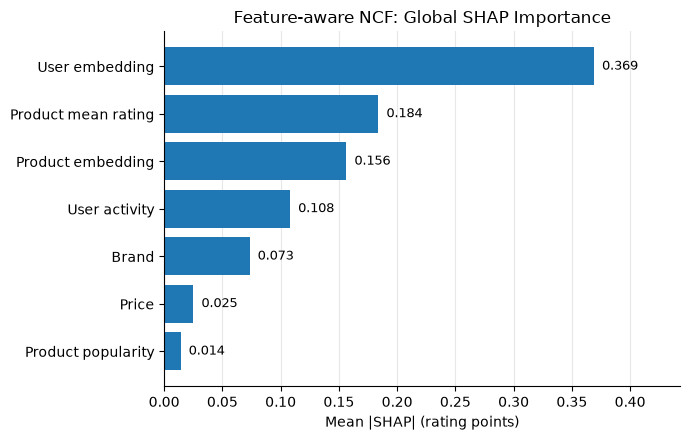

In [111]:
# Visualise Global SHAP importance: mean |SHAP| per input group
importance = (
    shap_grouped
    .abs()
    .mean()
    .sort_values()
)

display_names = {
    'user embedding': 'User embedding',
    'product embedding': 'Product embedding',
    'brand embedding': 'Brand',
    'price_usd': 'Price',
    'product_mean_rating': 'Product mean rating',
    'product_popularity': 'Product popularity',
    'user_interaction_counts': 'User activity'
}

labels = [display_names.get(x, x) for x in importance.index]

fig, ax = plt.subplots(figsize=(7, 4.5))

bars = ax.barh(
    labels,
    importance.values
)

for bar, value in zip(bars, importance.values):
    ax.text(
        value,
        bar.get_y() + bar.get_height() / 2,
        f'  {value:.3f}',
        va='center',
        fontsize=9
    )

ax.set_xlim(0, importance.max() * 1.2)
ax.set_xlabel('Mean |SHAP| (rating points)')
ax.set_title('Feature-aware NCF: Global SHAP Importance')
ax.set_axisbelow(True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

In [112]:
# Compare learned user and product embeddings with added side features

side_features = [
    'brand embedding',
    'price_usd',
    'product_mean_rating',
    'product_popularity',
    'user_interaction_counts'
]

id_embeddings = [
    'user embedding',
    'product embedding'
]

side_share = (
    importance[side_features].sum() / importance.sum() * 100
)

id_share = (
    importance[id_embeddings].sum() / importance.sum() * 100
)

print(
    f'Side features: {side_share:.1f}% | '
    f'Learned user/product representations: {id_share:.1f}%'
)

Side features: 43.5% | Learned user/product representations: 56.5%


**Global Importance**
The Feature-aware NCF relies heavily on user embeddings (0.369), followed by engineered features - product mean rating (0.184), product popularity (0.156) - followed by product embeddings (0.108).

Collectively, learned user and product representations account for 56.5% of total SHAP importance, while engineered features contribute a meaningful 43.5%. 

### 13.2. Local Importance

The example was selected as the highest predicted rating not exceeding 5, with an absolute prediction error below 0.5.

In [113]:
# Select a well-predicted, high-prediction example
local_examples = pd.DataFrame({
    'prediction': explain_predictions,
    'actual': explain_ratings})

local_examples['abs_error'] = np.abs(
    local_examples['prediction'] - local_examples['actual'])

example_idx = (local_examples[
        (local_examples['abs_error'] < 0.5) &
        (local_examples['prediction'] <= 5)]['prediction'].idxmax())

# Retrieve the validation observation
user_idx = int(explain_users[example_idx])
product_idx = int(explain_products[example_idx])

example = validation[
    (validation['user_idx'] == user_idx) &
    (validation['product_idx'] == product_idx)
].iloc[0]

print('Product ID:', example['product_id'])
print('Product:', example['product_name'])
print('Brand:', example['brand_name'])
print('Price:', example['price_usd'],'$')
print('Actual rating:', example['rating'])
print('Predicted rating:', round(explain_predictions[example_idx], 3))
print('Absolute error:', round(local_examples.loc[example_idx, 'abs_error'], 3))

Product ID: P377561
Product: FIRMx Exfoliating Peel Gel
Brand: Peter Thomas Roth
Price: 49.0 $
Actual rating: 5
Predicted rating: 5.0
Absolute error: 0.0


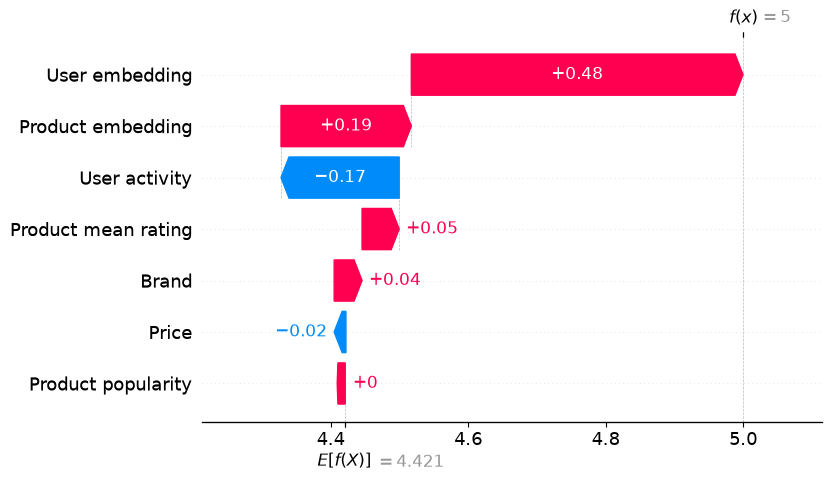

In [114]:
# Local SHAP explanation for selected validation example
local_shap = shap.Explanation(
    values=shap_grouped.iloc[example_idx].values,
    base_values=shap_base_value,
    feature_names=[
        display_names.get(name, name)
        for name in shap_grouped.columns
    ]
)

shap.plots.waterfall(
    local_shap,
    max_display=7
)

plt.show()

**Local Explanation:**

For this product (FIRMx Exfoliating Peel Gel), a high predicted rating was primarily driven by learned user rating behaviours (+0.48 rating points) and learned product representations (+0.19), while user activity (-0.17) and price (-0.02) contributed negatively to the rating prediction.

**Takeaway:**
Although the local example aligns with the global importance of the user and product embeddings, it also illustrates that contributions can vary from the aggregated pattern. An input with high average importance globally may contribute little to an individual prediction.

## 14. Subgroup Diagnostics 

### 14.1. User Activity Analysis

For the subgroup diagnostic analysis, I grouped test users by the number of interactions they had in the training set and then calculated rating-prediction accuracy (RMSE) on their held-out test ratings.

*Note: Users needed at least 3 interactions to contribute to training (1), validation (1), and testing (1). A user with 3 original interactions has 1 training interaction and belongs to the low-activity group, whereas a user with 6 interactions has 4 training interactions and belongs to the higher-activity group.*

* Low activity (1 training interaction): 40.4%
* Medium (2-3 training interactions): 33.1%
* Higher activity  (4 or more training interactions): 26.5%


In [115]:
# Group users based on the training interactions
train_user_activity = train.groupby('user_idx').size()

print(f'1 interaction: {(train_user_activity == 1).mean() * 100:.1f}%')
print(f'2-3 interactions: {((train_user_activity >= 2) & (train_user_activity <= 3)).mean() * 100:.1f}%')
print(f'>=4 interactions: {(train_user_activity >= 4).mean() * 100:.1f}%')

1 interaction: 40.4%
2-3 interactions: 33.1%
>=4 interactions: 26.5%


In [116]:
# Add training activity to test set
test_subgroups = test.merge(
    train_user_activity.rename('train_interactions'),
    on='user_idx',
    how='left'
)

# Define 3 activity groups
test_subgroups['user_activity_group'] = np.select(
    [
        test_subgroups['train_interactions'] == 1,
        test_subgroups['train_interactions'].between(2, 3),
        test_subgroups['train_interactions'] >= 4
    ],
    [
        'Low activity (1)',
        'Moderate activity (2-3)',
        'Higher activity (>=4)'
    ],
    default='Unknown'
)

test_subgroups['user_activity_group'].value_counts()

user_activity_group
Low activity (1)           42258
Moderate activity (2-3)    34547
Higher activity (>=4)      27567
Name: count, dtype: int64

In [117]:
# Test RMSE by user activity group
activity_groups = [
    'Low activity (1)',
    'Moderate activity (2-3)',
    'Higher activity (>=4)'
]

subgroup_rmse = []

for model_name, model in final_models.items():
    model.eval()

    with torch.no_grad():
        users = torch.tensor(
            test_subgroups['user_idx'].to_numpy(),
            dtype=torch.long
        )
        products = torch.tensor(
            test_subgroups['product_idx'].to_numpy(),
            dtype=torch.long
        )
        predictions = model(users, products).numpy()

    for group in activity_groups:
        mask = test_subgroups['user_activity_group'] == group

        rmse = root_mean_squared_error(
            test_subgroups.loc[mask, 'rating'],
            predictions[mask]
        )

        subgroup_rmse.append({
            'Model': model_name,
            'User activity': group,
            'Test RMSE': rmse
        })

subgroup_rmse_df = pd.DataFrame(subgroup_rmse)

subgroup_rmse_df.round(4)

,Model,User activity,Test RMSE
0,Biased MF,Low activity (1),1.1178
1,Biased MF,Moderate activity (2-3),1.0839
2,Biased MF,Higher activity (>=4),1.0474
3,Base NCF,Low activity (1),1.1404
4,Base NCF,Moderate activity (2-3),1.1163
5,Base NCF,Higher activity (>=4),1.0667
6,Feature-aware NCF,Low activity (1),1.1652
7,Feature-aware NCF,Moderate activity (2-3),1.1368
8,Feature-aware NCF,Higher activity (>=4),1.0762


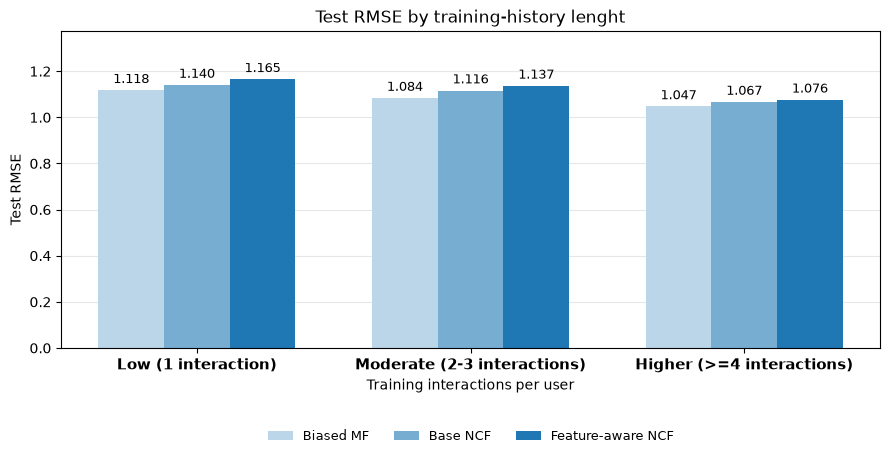

In [118]:
# Visualise Test RMSE by user training history lenght
model_colours = {
    'Biased MF': '#BBD6E8',
    'Base NCF': '#78ADD2',
    'Feature-aware NCF': '#1F77B4'
}

x = np.arange(len(activity_groups))
width = 0.24

fig, ax = plt.subplots(figsize=(9, 4.8))

for i, model in enumerate(model_colours):
    group_data = (
        subgroup_rmse_df[subgroup_rmse_df['Model'] == model]
        .set_index('User activity')['Test RMSE']
        .reindex(activity_groups)
    )

    bars = ax.bar(
        x + (i - 1) * width,
        group_data,
        width=width,
        color=model_colours[model],
        label=model
    )

    ax.bar_label(bars, fmt='%.3f', padding=3, fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(
    ['Low (1 interaction)', 'Moderate (2-3 interactions)', 'Higher (>=4 interactions)'],
    fontsize=11,
    fontweight='bold'
)

ax.legend(
    loc='upper center',
    bbox_to_anchor=(0.5, -0.22),
    ncol=3,
    frameon=False,
    fontsize=9
)
ax.set_xlabel('Training interactions per user')
ax.set_ylabel('Test RMSE')
ax.set_title('Test RMSE by training-history lenght')
ax.set_ylim(0, subgroup_rmse_df['Test RMSE'].max() * 1.18)

ax.set_axisbelow(True)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

**Subgroups Results:**
All 3 models achieved lower RMSE for higher-activity users (4 or more) than for low-activity users, indicating that user activity is critical for achieving higher prediction accuracy. RMSE gradually improves as user interactions increase. Biased MF achieved the lowest RMSE across all activity groups.

**Business implication:** The fewer interactions users have, the worse recommendations they will receive. This is a major business challenge, especially since a large share of users are low-engagement in this dataset.

### 14.2. Skin Tone Analysis

For the ethical analysis, I examined skin tone information, as it is relevant to group representation and may impacts product recommendations. Because skin tone is a sensitive, self-reported attribute, I excluded it from the model and retained it solely for subgroup audit.
The skin-tone analysis follows the same principle as the subgroup activity analysis, comparing test RMSE across different skin-tone categories.

In [119]:
# Calculate count of skin tone categories in test set
test['skin_tone'].value_counts(dropna=False)

skin_tone
light          27858
fair           21659
lightMedium    19033
NaN            10909
medium          7024
mediumTan       5992
fairLight       5879
tan             3228
deep            1959
rich             487
porcelain        160
olive            131
dark              46
notSureST          7
Name: count, dtype: int64

In [120]:
# Calculate missingness in test set
missing_pct = test['skin_tone'].isna().mean() * 100
available_pct = test['skin_tone'].notna().mean() * 100

print(f'Skin tone test available: {available_pct:.1f}%')
print(f'Skin tone test missing: {missing_pct:.1f}%')

Skin tone test available: 89.5%
Skin tone test missing: 10.5%


In [121]:
# Test RMSE by skin tone
skin_tone_results = []

for model_name, model in final_models.items():
    model.eval()

    with torch.no_grad():
        users = torch.tensor(test['user_idx'].to_numpy(), dtype=torch.long)
        products = torch.tensor(test['product_idx'].to_numpy(), dtype=torch.long)
        predictions = model(users, products).numpy()

    for tone in test['skin_tone'].dropna().unique():
        mask = test['skin_tone'] == tone    #adjust to the skin type

        rmse = root_mean_squared_error(
            test.loc[mask, 'rating'],
            predictions[mask]
        )

        skin_tone_results.append({
            'Skin tone': tone,
            'Count': mask.sum(),
            'Model': model_name,
            'Test RMSE': rmse
        })

skin_tone_results = pd.DataFrame(skin_tone_results)

skin_tone_table = skin_tone_results.pivot(
    index=['Skin tone', 'Count'],
    columns='Model',
    values='Test RMSE'
).reset_index()

skin_tone_table = skin_tone_table[
    ['Skin tone', 'Count', 'Biased MF', 'Base NCF', 'Feature-aware NCF']
]

skin_tone_table.round(4)

Model,Skin tone,Count,Biased MF,Base NCF,Feature-aware NCF
0,dark,46,1.2711,1.2828,1.2720
1,deep,1959,1.1016,1.1227,1.1519
2,fair,21659,1.1026,1.1264,1.1486
3,fairLight,5879,1.1198,1.1465,1.1552
4,light,27858,1.1031,1.1282,1.1460
5,lightMedium,19033,1.0801,1.1062,1.1212
6,medium,7024,1.0686,1.0955,1.1157
7,mediumTan,5992,1.1297,1.1507,1.1706
8,notSureST,7,1.1243,1.1584,1.0591
9,olive,131,1.3567,1.3482,1.3316


**Results:**
Skin-tone information has good coverage (90%), but representation across the 12 categories is highly uneven. Smaller groups show both the highest and lowest test RMSE values, while larger groups are generally in the middle range, with Biased MF performing better for them across all models.
No clear patterns emerge between group size and prediction error. These estimates are less stable and warrant monitoring.  

### 15. Final Model Demonstration

**Setup:** 
In this demonstration, I evaluate performance across 3 final models by inspecting a product’s predicted rating and evaluating where it ranks within the 100-candidate set used for NDCG@10.

I selected a user with 8 training interactions from the higher-activity group (>=4 interactions) from a randomly generated sample. The customer actually rates the product 5 stars.


In [122]:
# Define demo candidate set from higher activity group
demo_candidates = test_subgroups[
    test_subgroups['train_interactions'] >= 4
]

demo_candidates[
    ['user_idx', 'product_name', 'brand_name', 'rating', 'train_interactions']
].sample(5, random_state=42)

,user_idx,product_name,brand_name,rating,train_interactions
42736,42922,Dr. Andrew Weil for Origins Mega-Mushroom Reli...,Origins,5,9
36770,36926,Retinol Firming Cream Treatment with Peptides ...,LANEIGE,4,5
77944,78331,100% Plant-Derived Squalane,The Ordinary,4,6
59971,60254,Honey Infused Lip Oil,Gisou,5,8
69198,69547,Squalane + Omega Repair Deep Hydration Moistur...,Biossance,2,7


In [123]:
# Set a demo condidate
demo_row = test_subgroups.loc[59971]

demo_user = int(demo_row['user_idx'])
demo_product = int(demo_row['product_idx'])
demo_actual = demo_row['rating']

In [124]:
# Final model demonstration
candidates = sampled_candidates[demo_user]

users = torch.full((len(candidates),), demo_user, dtype=torch.long)
products = torch.tensor(candidates, dtype=torch.long)

results = []

for model_name, model in final_models.items():
    model.eval()

    with torch.no_grad():
        scores = model(users, products).numpy()

    predicted_rating = scores[0]
    rank = (scores > predicted_rating).sum() + 1

    results.append([
        model_name,
        round(predicted_rating, 2),
        int(rank)
    ])

demo_results = pd.DataFrame(
    results,
    columns=["Model", "Predicted rating", "Rank in 100"]
)

# Display demo condidate information
print(f"Product: {demo_row['product_name']}")
print(f"Brand: {demo_row['brand_name']}")
print(f"Training interactions: {int(demo_row['train_interactions'])}")
print(f"Actual rating: {demo_actual:.1f}\n")

display(demo_results)

Product: Honey Infused Lip Oil
Brand: Gisou
Training interactions: 8
Actual rating: 5.0



,Model,Predicted rating,Rank in 100
0,Biased MF,4.61,7
1,Base NCF,3.93,59
2,Feature-aware NCF,3.33,83


**Result:**
All 3 models predicted a lower rating than the actual one (5-star rating). Interestingly, for this demo product, Biased MF not only predicts the rating score more accurately than the NCF models but also ranks it in the top 10. The neural models rank the product considerably lower, which contrasts with the global (aggregated) evaluation where Feature-aware NCF achieved the highest NDCG@10. This example shows that a single recommendation does not represent overall model performance and suggests that aggregated performance can hide variation at the user level.

## 16. Saving final models 

In [ ]:
# Saving the models weights

from pathlib import Path
from datetime import datetime

save_dir = Path("saved_models") / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
save_dir.mkdir(parents=True, exist_ok=False)

for name, model in final_models.items():
    path = save_dir / f"{name.replace(' ', '_')}_final.pt"
    torch.save(model.state_dict(), path)
    print(f"Saved {name} -> {path}")

print("Saved in:", save_dir)

## References

Cañamares, R., Castells, P. and Moffat, A. (2020) ‘Offline evaluation options for recommender systems’, Information Retrieval Journal, 23(4), pp. 387–410. Available at: https://doi.org/10.1007/s10791-020-09371-3

Chen, W.-H., et al. (2020) 'Attribute-Aware Recommender System Based on Collaborative Filtering: Survey and Classification', Frontiers in Big Data, 2, Article 49. Available at: https://doi.org/10.3389/fdata.2019.00049

Géron, A. (2022) Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow, 3rd edn. Sebastopol, CA: O'Reilly Media. 

Ghosh, S. et al. (2026) ‘Dual stream adaptive sequential recommendation’, Discover Artificial Intelligence, 6, article 1201. Available at: https://doi.org/10.1007/s44163-026-02282-0

Goodfellow, I., Bengio, Y. and Courville, A. (2016) Deep Learning. MIT Press. Chapter 11: ‘Practical methodology’. Available at: https://www.deeplearningbook.org/contents/guidelines.html (Accessed: 9 October 2026).

Harris, C.R. et al. (2020) ‘Array programming with NumPy’, Nature, 585, pp. 357–362. Available at: https://doi.org/10.1038/s41586-020-2649-2

He, X., et al. (2017) ‘Neural collaborative filtering’, Proceedings of the 26th International Conference on World Wide Web (WWW ’17), Perth, Australia, pp. 173–182. Available at: https://doi.org/10.1145/3038912.3052569

Inky, N. (2023) Sephora products and skincare reviews [dataset]. Kaggle. Available at: https://www.kaggle.com/datasets/nadyinky/sephora-products-and-skincare-reviews (Accessed 13 September 2026).

Meng, Z., et al. (2020) ‘Exploring data splitting strategies for the evaluation of recommendation models’, arXiv [Preprint]. Available at: https://doi.org/10.48550/arXiv.2007.13237

Molnar, C. (2023) Interpretable machine learning: A guide for making black box models explainable. 2nd edn. Available at: https://christophm.github.io/interpretable-ml-book (Accessed: 3 October 2026).

Paszke, A. et al. (2019) ‘PyTorch: An imperative style, high-performance deep learning library’, Advances in Neural Information Processing Systems, 32. Available at: https://arxiv.org/abs/1912.01703 (Accessed: 3 October 2026).

Pedregosa, F. et al. (2011) ‘Scikit-learn: Machine learning in Python’, Journal of Machine Learning Research, 12, pp. 2825–2830. Available at: https://www.jmlr.org/papers/v12/pedregosa11a.html (Accessed: 3 October 2026).

SHAP (n.d.-a) API examples: Plots. Available at: https://shap.readthedocs.io/en/latest/api_examples.html#plots (Accessed: 2 October 2026).

SHAP (n.d.-b) ‘shap.DeepExplainer’, SHAP documentation. Available at: https://shap.readthedocs.io/en/latest/generated/shap.DeepExplainer.html (Accessed: 2 October 2026).

Singh, A.P., Dwivedi, V.K. and Gautam, C.S. (2026) ‘Neural collaborative filtering-based personalized recommendation system using Amazon Beauty dataset’, International Research Journal of Computer Science, 13(6), pp. 592–600. Available at: https://www.irjcs.com/volumes/Vol13/iss-06/01.JNCS10083.pdf (Accessed: 3 October 2026).

Smith, L.N. (2018) ‘A disciplined approach to neural network hyper-parameters: Part 1—learning rate, batch size, momentum, and weight decay’, arXiv [Preprint]. Available at: https://doi.org/10.48550/arXiv.1803.09820

Zhang, A., et al. (2023) Dive into deep learning. Cambridge: Cambridge University Press. Section 21.3, ‘Matrix factorization’. Available at: https://d2l.ai/chapter_recommender-systems/mf.html (Accessed: 3 October 2026).

Yuan, H. and Hernandez, A.A. (2023) ‘User cold start problem in recommendation systems: A systematic review’, IEEE Access, 11, pp. 136958–136977. Available at: https://doi.org/10.1109/ACCESS.2023.3338705
